In [95]:
import xarray as xr
import os
import pandas as pd
input_file = 'wiam/MYD13A1.006_500m_aid0001.nc' 
# Open the dataset
ds = xr.open_dataset(input_file)

In [96]:
import pandas as pd
import cftime

# Extract the "time" coordinate from the dataset
time_values = ds['time'].values

# Convert each cftime.DatetimeJulian object to a Python datetime object
time_datetime = [cftime.datetime.strftime(dt, "%Y-%m-%d %H:%M:%S") for dt in time_values]

# Convert the list of strings to a pandas datetime series
ds['time'] = pd.to_datetime(time_datetime)


In [97]:
ds

<xarray.Dataset>
Dimensions:         (time: 4746, ydim: 1857, xdim: 1845)
Coordinates:
  * time            (time) datetime64[ns] 2003-01-01 2003-01-02 ... 2015-12-31
  * ydim            (ydim) float64 4.006e+06 4.005e+06 ... 2.287e+06 2.286e+06
  * xdim            (xdim) float64 -1.803e+06 -1.802e+06 ... -9.405e+04
Data variables:
    crs             int8 ...
    BAND20ALBEDO_1  (time, ydim, xdim) float32 ...
Attributes:
    title:        MYDTBGA.006 for aid0001
    Conventions:  CF-1.6
    institution:  Land Processes Distributed Active Archive Center (LP DAAC)
    source:       AppEEARS v3.31
    references:   See README.md
    history:      See README.md

In [98]:
import os
import xarray as xr
from datetime import date

output_dir = 'wiam/MYD13A1.006_500m_aid0001'
os.makedirs(output_dir, exist_ok=True) 

import os
import xarray as xr


# Extract date values from time DataArray
dates = ds.time.dt.date  

for t, date in zip(ds.time, dates):

  # Slice Dataset 
  ds_t = ds.sel(time=t)  

  # Build filename using date
  filename = f"{output_dir}/MYD13A1.006_500m_aid0001_{date.values}.nc"
  
  ds_t['time'] = t
  # Write netCDF 
  ds_t.to_netcdf(filename)

c:\Users\Lahcen.OUSAYD\Anaconda3\lib\site-packages\xarray\core\accessor_dt.py:72: FutureWarning: Index.ravel returning ndarray is deprecated; in a future version this will return a view on self.
  values_as_series = pd.Series(values.ravel(), copy=False)


KeyboardInterrupt: 

In [83]:

# File paths
orig_file = 'wiam/MYD13A1.006_500m_aid0001.nc' 
# Open original and get time coord
orig_ds = xr.open_dataset(orig_file)
time_coord = orig_ds['time']

In [89]:
orig_ds

<xarray.Dataset>
Dimensions:                   (time: 311, ydim: 3714, xdim: 3689)
Coordinates:
  * time                      (time) object 2002-07-04 00:00:00 ... 2015-12-2...
  * ydim                      (ydim) float64 4.006e+06 4.006e+06 ... 2.286e+06
  * xdim                      (xdim) float64 -1.803e+06 ... -9.382e+04
Data variables:
    crs                       int8 ...
    _500m_16_days_NDVI        (time, ydim, xdim) float32 ...
    _500m_16_days_VI_Quality  (time, ydim, xdim) float64 ...
Attributes:
    title:        MYD13A1.006 for aid0001
    Conventions:  CF-1.6
    institution:  Land Processes Distributed Active Archive Center (LP DAAC)
    source:       AppEEARS v3.29
    references:   See README.md
    history:      See README.md

In [91]:
import xarray as xr

orig_ds = xr.open_dataset('wiam/MYD13A1.006_500m_aid0001.nc')
comb_ds = xr.open_mfdataset('wiam/MYD13A1.006_25km_aid0001/*.nc')

# Add time coord from original to combined
comb_ds['time'] = orig_ds['time']

# Save combined dataset
comb_ds.to_netcdf('wiam/MYD13A1.006_25km_aid0001.nc')

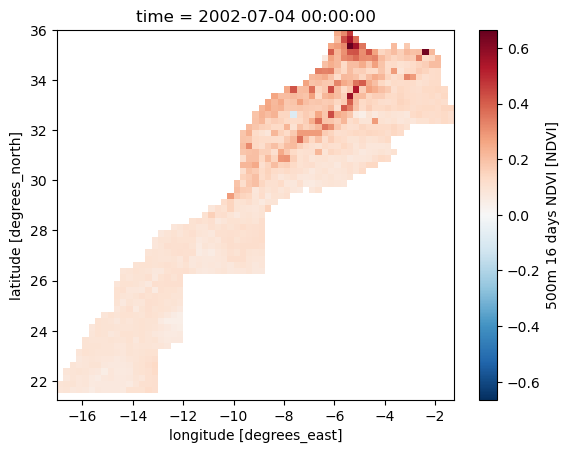

In [94]:
comb_ds['_500m_16_days_NDVI'][0].plot()

In [2]:
cube_character = "M\u00B3"
print(cube_character)

M³


In [2]:
import scipy.io
import xarray as xr
import numpy as np
import datetime

In [3]:
import scipy.io
import xarray as xr
import numpy as np
import datetime
import os

# Load the .mat file
mat_data = scipy.io.loadmat('SM_CCI_month.mat')  # Replace with the actual file name

# Create an empty list to store datasets
datasets = []

# Iterate through each month's data
for year in range(1979, 2020):  # Update the range based on your data
    for month in range(1, 13):
        # Construct the variable name for the current month
        var_name = f'SM_{year:04}_{month:02}'

        # Extract the variable data for the current month
        variable_data = mat_data[var_name]

        # Create an xarray Dataset
        ds = xr.Dataset(
            data_vars={
                'SM': (['latitude', 'longitude'], variable_data)
            },
            coords={
                'latitude': np.linspace(40, -40, variable_data.shape[0]),
                'longitude': np.linspace(-20, 60, variable_data.shape[1]),
                'time': np.array([datetime.datetime(year, month, 1)], dtype='datetime64')
            }
        )

        # Add the dataset to the list
        datasets.append(ds)

# Concatenate the list of datasets along the time dimension
combined_ds = xr.concat(datasets, dim='time')

# Save the combined dataset to a NetCDF file
#combined_ds.to_netcdf('combined_SM_data.nc', format='NETCDF4')

# ...


In [4]:
import xarray as xr

# Load the existing dataset
dataset = combined_ds
# Define the time period you're interested in
# Define the time period you're interested in
start_year = 1981
end_year = 2015

# Create a list to store the extracted seasons
seasons = []

# Loop through the years and extract each growing season
for year in range(start_year, end_year + 1):
    # Select the months from November to May for each year
    season = dataset.sel(time=slice(f'{year}-10', f'{year + 1}-05'))
    seasons.append(season)

# Concatenate the extracted seasons along the time dimension
wheat_growing_season = xr.concat(seasons, dim='time')

# Save the extracted data to a new NetCDF file
wheat_growing_season.to_netcdf('SM_1979_2019/SM_wheat_growing_1982_2016_season.nc')


In [5]:
#ds = ds.drop('spatial_ref')
import geopandas as gpd

# Load the shapefiles for the five regions
region1_path = "All_55km/shapefiles/MarrakechSafi/MarrakechSafi.shp"
region2_path = "All_55km/shapefiles/BeniMellalKhenifra/BeniMellalKhenifra.shp"
region3_path = "All_55km/shapefiles/CasablancaSettat/CasablancaSettat.shp"
region4_path = "All_55km/shapefiles/FesMeknes/FesMeknes.shp"
region5_path = "All_55km/shapefiles/RabatSaleKenitra/"

# Read the shapefiles into GeoDataFrames
r1 = gpd.read_file(region1_path)
r2 = gpd.read_file(region2_path)
r3 = gpd.read_file(region3_path)
r4 = gpd.read_file(region4_path)
r5 = gpd.read_file(region5_path)

temp = wheat_growing_season
temp = temp.rio.write_crs(r1.crs)

ms = temp.rio.clip(r1.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      r1.crs)
ms.to_netcdf('SM_1979_2019/SM_Marrakech_safi_wheat_growing_1982_2016_season.nc')
# Calculate the spatial average of SM values across all time steps
spatial_average = ms['SM'].mean(dim='time')
# Save the spatial average data to a new NetCDF file
spatial_average.to_netcdf('SM_1979_2019/SM_Marrakech_safi_AVG_wheat_growing_1982_2016_season.nc')


bmk = temp.rio.clip(r2.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      r2.crs)
bmk.to_netcdf('SM_1979_2019/SM_Beni Mellal_Khenifra_wheat_growing_1982_2016_season.nc')
spatial_average = bmk['SM'].mean(dim='time')
# Save the spatial average data to a new NetCDF file
spatial_average.to_netcdf('SM_1979_2019/SM_Beni Mellal_Khenifra_AVG_wheat_growing_1982_2016_season.nc')


cs = temp.rio.clip(r3.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      r3.crs)
cs.to_netcdf('SM_1979_2019/SM_Casa_Settat_wheat_growing_1982_2016_season.nc')
spatial_average = cs['SM'].mean(dim='time')
# Save the spatial average data to a new NetCDF file
spatial_average.to_netcdf('SM_1979_2019/SM_Casa_Settat_AVG_wheat_growing_1982_2016_season.nc')


fm = temp.rio.clip(r4.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      r4.crs)
fm.to_netcdf('SM_1979_2019/SM_FesMeknes_wheat_growing_1982_2016_season.nc')
spatial_average = fm['SM'].mean(dim='time')
# Save the spatial average data to a new NetCDF file
spatial_average.to_netcdf('SM_1979_2019/SM_FesMeknes_AVG_wheat_growing_1982_2016_season.nc')


rsk = temp.rio.clip(r5.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      r5.crs)
rsk.to_netcdf('SM_1979_2019/SM_Rabat_Sale_kenitra_wheat_growing_1982_2016_season.nc')
spatial_average = rsk['SM'].mean(dim='time')
# Save the spatial average data to a new NetCDF file
spatial_average.to_netcdf('SM_1979_2019/SM_Rabat_Sale_Kenitra_AVG_wheat_growing_1982_2016_season.nc')

In [31]:
import pandas as pd
import plotly.graph_objs as go

# List of Excel file names and corresponding regions
excel_files = ['SM_1979_2019/Monthly_SM/SM_Beni_Mellal_Khenifra_monthly_avg.xlsx',
               'SM_1979_2019/SM_Beni Mellal_Khenifra_wheat_growing_1982_2016_season.xlsx',
               'SM_1979_2019/SM_Casa_Settat_wheat_growing_1982_2016_season.xlsx', 
               'SM_1979_2019/SM_FesMeknes_wheat_growing_1982_2016_season.xlsx', 
               'SM_1979_2019/SM_Rabat_Sale_kenitra_wheat_growing_1982_2016_season.xlsx']

regions = ['Marrakech Safi', 'Beni Mellal Khenifra', 'Casablanca Settat', 'Fes Meknes', 'Rabat Sale Kenitra']

# Define colors for each region's line
line_colors = ['black', 'blue', 'green', 'red', 'purple']

# Initialize figure with simple_white layout
fig = go.Figure(layout=go.Layout(template='simple_white'))

for excel_file, region, color in zip(excel_files, regions, line_colors):
    # Read the Excel file into a DataFrame
    seasonal_avg_df = pd.read_excel(excel_file)
    
    # Add trace to the figure with specified line color
    fig.add_trace(go.Scatter(x=seasonal_avg_df['Year'], y=seasonal_avg_df['Soil_M'],
                             mode='lines+markers', name=region, line_color=color))

# Customize layout
fig.update_layout(title='Average Soil Moisture Over Wheat Growing Season',
                  xaxis_title='Year',
                  yaxis_title='Average Soil Moisture (m³/m³)',
                  #legend=dict(title='Regions'),
                  xaxis=dict(gridcolor='whitesmoke'), # Set x-axis grid color to whitesmoke
                  yaxis=dict(gridcolor='whitesmoke')) # Set y-axis grid color to whitesmoke

# Show the figure
fig.show()


In [69]:
import xarray as xr
import pandas as pd

# Load the existing dataset
dataset = xr.open_dataset('SM_1979_2019/SM_Rabat_Sale_kenitra_wheat_growing_1982_2016_season.nc')

# Define the years for wheat growing seasons
start_year = 1981
end_year = 2016

# Initialize lists to store year and average soil moisture values
years = []
soil_moisture_averages = []

# Loop through the years, calculate the seasonal average, and store values
for year in range(start_year, end_year + 1):
    start_date = f'{year - 1}-10-01'
    end_date = f'{year}-05-01'
    season_data = dataset.sel(time=slice(start_date, end_date))
    seasonal_average = season_data.mean(dim='time')['SM'].mean().item()
    years.append(year)
    soil_moisture_averages.append(seasonal_average)

# Create a DataFrame with the year and average soil moisture values
data = {"Year": years, "Soil_M": soil_moisture_averages}
seasonal_avg_df = pd.DataFrame(data)

# Drop the first row (1981)
seasonal_avg_df = seasonal_avg_df[seasonal_avg_df['Year'] != 1981]

# Save the DataFrame to an Excel file
seasonal_avg_df.to_excel('SM_1979_2019/SM_Rabat_Sale_kenitra_wheat_growing_1982_2016_season.xlsx', index=False)


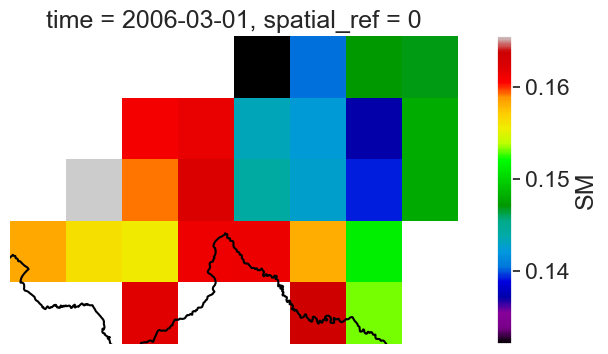

In [14]:
f, ax = plt.subplots(figsize=(10, 4))

r1.boundary.plot(ax=ax,color='black')
cs['SM'][302].plot(ax=ax,
                            cmap = 'nipy_spectral',shading='auto'    )
#ax.set(title="Raster Layer Cropped to Geodataframe Extent")
ax.set_axis_off()
plt.show()

In [20]:
# Load the two NetCDF files
ds2 = xr.open_dataset('SM_1979_2019/monthly_netcdf/SM_Beni_Mellal_Khenifra_wheat_growing_1982_2016_season_55KM.nc')
ds1 = xr.open_dataset('SM_1979_2019/monthly_netcdf/M_HArea.nc')

# Identify common coordinates
common_coords = ds1.coords.keys() & ds2.coords.keys()

# Extract overlapping region based on common coordinates
overlapping_ds1 = ds1.sel({coord: ds1[coord] for coord in common_coords})
overlapping_ds2 = ds2.sel({coord: ds2[coord] for coord in common_coords})

# Merge the two overlapping datasets
intersection = xr.merge([overlapping_ds1, overlapping_ds2])

# Save the intersection to a new NetCDF file
intersection.to_netcdf('SM_1979_2019/monthly_netcdf/ha_sm/SM_ha_Beni_Mellal_Khenifra_wheat_growing_1982_2016_season_55KM.nc')

In [25]:
import xarray as xr
import pandas as pd

# Load the existing dataset
dataset = xr.open_dataset('SM_1979_2019/monthly_netcdf/ha_sm/SM_ha_Rabat_Sale_kenitra_wheat_growing_1982_2016_season_55KM.nc')

# Define the start and end years
start_year = 1982
end_year = 2016

# Create empty lists to store the results
months = ['October', 'November', 'December', 'January', 'February', 'March', 'April', 'May']
avg_monthly_data = {month: [] for month in months}

# Loop through each month
for month in months:
    for year in range(start_year, end_year + 1):
        # Select the data for the specific year and month
        selected_data = dataset.sel(time=f'{year}-{month[:3]}', method='nearest')

        # Calculate the average soil moisture for the month
        avg_monthly = selected_data['SM'].mean().item()

        # Append the average soil moisture to the list for the specific month
        avg_monthly_data[month].append(avg_monthly)

# Create a DataFrame from the dictionary
monthly_avg_df = pd.DataFrame(avg_monthly_data)

# Add the Year column to the DataFrame
monthly_avg_df.insert(0, 'Year', list(range(start_year, end_year + 1)))

# Set 'Year' column as the index
monthly_avg_df.set_index('Year', inplace=True)
# Save the DataFrame to an Excel file with correct formatting
output_path = 'SM_1979_2019/Monthly_SM/SM_Rabat_Sale_kenitra_monthly_avg.xlsx'
monthly_avg_df.to_excel(output_path, sheet_name='Monthly_Averages', float_format="%.2f")

monthly_avg_df.head()


,October,November,December,January,February,March,April,May
Year,,,,,,,,
1982,0.166699,0.184953,0.200793,0.172612,0.189341,0.201108,0.201444,0.188209
1983,0.243241,0.228121,0.189837,0.159760,0.172309,0.186722,0.141131,0.183998
1984,0.145529,0.190637,0.192983,0.134145,0.191699,0.174366,0.160104,0.160614
1985,0.176104,0.199062,0.180986,0.194361,0.228497,0.238879,0.101114,0.167466
1986,0.201334,0.184627,0.209109,0.180879,0.260396,0.108386,0.164540,0.163263


In [40]:
import pandas as pd
import plotly.graph_objs as go

# List of Excel file names and corresponding regions
excel_files = [
    'SM_1979_2019/SM_Marrakech_safi_wheat_growing_1982_2016_season.xlsx',
    'SM_1979_2019/SM_Beni Mellal_Khenifra_wheat_growing_1982_2016_season.xlsx',
    'SM_1979_2019/SM_Casa_Settat_wheat_growing_1982_2016_season.xlsx', 
    'SM_1979_2019/SM_FesMeknes_wheat_growing_1982_2016_season.xlsx', 
    'SM_1979_2019/SM_Rabat_Sale_kenitra_wheat_growing_1982_2016_season.xlsx'
]

regions = ['Marrakech Safi', 'Beni Mellal Khenifra', 'Casablanca Settat', 'Fes Meknes', 'Rabat Sale Kenitra']


# Define colors for each region's line
line_colors = ['red']

# Initialize figure with simple_white layout
fig = go.Figure(layout=go.Layout(template='simple_white'))

for excel_file, region, color in zip(excel_files, regions, line_colors):
    # Read the Excel file into a DataFrame
    seasonal_avg_df = pd.read_excel(excel_file)
    
    # Add trace for November data
    fig.add_trace(go.Scatter(x=seasonal_avg_df['Year'], y=seasonal_avg_df['November'],
                             mode='lines+markers', name=f'{region} - November', line_color=color))
    
    # Add trace for Yield data on a secondary y-axis
    fig.add_trace(go.Scatter(x=seasonal_avg_df['Year'], y=seasonal_avg_df['Yield'],
                             mode='lines+markers', name=f'{region} - Yield', line_color=color,
                             yaxis='y2'))

# Customize layout
fig.update_layout(title='Average Soil Moisture Over Wheat Growing Season',
                  xaxis_title='Year',
                  yaxis_title='Average Soil Moisture (m³/m³)',
                  xaxis=dict(gridcolor='whitesmoke'), # Set x-axis grid color to whitesmoke
                  yaxis=dict(gridcolor='whitesmoke'), # Set y-axis grid color to whitesmoke
                  yaxis2=dict(title='Yield', overlaying='y', side='right')) # Secondary y-axis for Yield data

# Show the figure
fig.show()


In [52]:
import pandas as pd
import plotly.graph_objs as go
from plotly.subplots import make_subplots

# List of Excel file names and corresponding regions
excel_files = [
    'SM_1979_2019/Monthly_SM/SM_Marrakech_Safi_monthly_avg.xlsx',
    'SM_1979_2019/Monthly_SM/SM_Beni_Mellal_Khenifra_monthly_avg.xlsx',
    'SM_1979_2019/Monthly_SM/SM_Casa_Settat_monthly_avg.xlsx', 
    'SM_1979_2019/Monthly_SM/SM_Fes_Meknes_monthly_avg.xlsx', 
    'SM_1979_2019/Monthly_SM/SM_Rabat_Sale_kenitra_monthly_avg.xlsx'
]

regions = ['Marrakech Safi', 'Beni Mellal Khenifra', 'Casablanca Settat', 'Fes Meknes', 'Rabat Sale Kenitra']


In [67]:
import pandas as pd
import plotly.graph_objs as go

# List of Excel file names and corresponding regions
excel_files = ['SM_1979_2019/Monthly_SM/SM_Fes_Meknes_monthly_avg.xlsx']

regions = ['Fes Meknes']

# Define colors for each region's line
line_colors = ['red','green']

# Initialize figure with simple_white layout
fig = go.Figure(layout=go.Layout(template='simple_white'))

for excel_file, region, color in zip(excel_files, regions, line_colors):
    # Read the Excel file into a DataFrame
    seasonal_avg_df = pd.read_excel(excel_file)
    
    # Add trace for November data
    fig.add_trace(go.Scatter(x=seasonal_avg_df['Year'], y=seasonal_avg_df['November'],
                             mode='lines+markers', name=f'{region} - November', line_color= line_colors[0]))
    
    # Add trace for Yield data on a secondary y-axis
    fig.add_trace(go.Scatter(x=seasonal_avg_df['Year'], y=seasonal_avg_df['Yield'],
                             mode='lines+markers', name=f'{region} - Yield', line_color= line_colors[1],
                             yaxis='y2'))

# Customize layout
fig.update_layout(title='',
                  xaxis_title='Year',
                  yaxis_title='Average Soil Moisture (m³/m³)',
                  xaxis=dict(gridcolor='whitesmoke'), # Set x-axis grid color to whitesmoke
                  yaxis=dict(gridcolor='whitesmoke'), # Set y-axis grid color to whitesmoke
                  yaxis2=dict(title='Yield', overlaying='y', side='right')) # Secondary y-axis for Yield data

# Show the figure
fig.show()


# End

In [1]:
%matplotlib inline
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
import pandas as pd
pd.pandas.set_option('display.max_columns',None)
pd.pandas.set_option('display.max_rows',None)

In [1]:
import netCDF4
import numpy as np
import xarray as xr
import pandas as pd 
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.offline as po
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
import matplotlib.pyplot as plt
import plotly.express as px
import random
import plotly.figure_factory as ff

In [2]:
import plotly.graph_objects as go
import plotly.offline as po
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
import matplotlib.pyplot as plt
import plotly.express as px
import random
import plotly.figure_factory as ff

In [5]:
path = 'wheat/TS'

In [6]:
os.listdir(path)

['yield_BeniMellalKhenifra_1982_2016.nc',
 'yield_CasablancaSettat_1982_2016.nc',
 'yield_DraaTafilalet_1982_2016.nc',
 'yield_FesMeknes_1982_2016.nc',
 'yield_MarrakechSafi_1982_2016.nc',
 'yield_Morocco_1981_2016.nc',
 'yield_Oriental_1982_2016.nc',
 'yield_RabatSaleKenitra_1982_2016.nc',
 'yield_SoussMassa_1982_2016.nc',
 'yield_TangerTetouanAlHoceima_1982_2016.nc']

In [8]:
bmk = xr.open_dataset(path+'/yield_BeniMellalKhenifra_1982_2016.nc')
cs = xr.open_dataset(path+'/yield_CasablancaSettat_1982_2016.nc')
dt = xr.open_dataset(path+'/yield_DraaTafilalet_1982_2016.nc')
fm = xr.open_dataset(path+'/yield_FesMeknes_1982_2016.nc')
ms = xr.open_dataset(path+'/yield_MarrakechSafi_1982_2016.nc')
m = xr.open_dataset(path+'/yield_Morocco_1981_2016.nc')
o = xr.open_dataset(path+'/yield_Oriental_1982_2016.nc')
rsk = xr.open_dataset(path+'/yield_RabatSaleKenitra_1982_2016.nc')
sm = xr.open_dataset(path+'/yield_SoussMassa_1982_2016.nc')
tth = xr.open_dataset(path+'/yield_TangerTetouanAlHoceima_1982_2016.nc')

In [9]:
tth

<xarray.Dataset>
Dimensions:    (time: 35, longitude: 4, latitude: 3)
Coordinates:
  * longitude  (longitude) float64 -5.75 -5.25 -4.75 -4.25
  * latitude   (latitude) float64 35.75 35.25 34.75
  * time       (time) datetime64[ns] 1982-01-01 1983-01-01 ... 2016-01-01
Data variables:
    crs        (time) int32 ...
    yield      (time, latitude, longitude) float32 ...

In [10]:
bmk1 = bmk.to_dataframe()

<center><h1 style='color:aqua'>Yield changes</h1></center>

In [11]:
all =  pd.read_excel('all_1982_2016.xlsx', header=[0, 1],index_col=0)
#ori =  pd.read_excel('Oriental.xlsx',index_col=0)
#rskx =  pd.read_excel('RabatSaleKenitra.xlsx',index_col=0)

In [12]:
all 

Morocco                                              \
Year      AY PY (max) PY (Mueller) YG (max) YG (Mueller)   
1982    0.78     1.97          4.1     1.19         3.32   
1983    0.60     1.97          4.1     1.37         3.50   
1984    0.62     1.97          4.1     1.35         3.48   
1985    0.77     1.97          4.1     1.20         3.33   
1986    1.04     1.97          4.1     0.93         3.06   
1987    0.65     1.97          4.1     1.32         3.45   
1988    1.08     1.97          4.1     0.89         3.02   
1989    0.90     1.97          4.1     1.07         3.20   
1990    0.82     1.97          4.1     1.15         3.28   
1991    1.14     1.97          4.1     0.83         2.96   
1992    0.47     1.97          4.1     1.50         3.63   
1993    0.48     1.97          4.1     1.49         3.62   
1994    1.17     1.97          4.1     0.80         2.93   
1995    0.39     1.97          4.1     1.58         3.71   
1996    1.23     1.97          4.1     0.74         2.87   
1997    0.60     1.97          4.1     1.37         3.50   
1998    0.89     1.97          4.1     1.08         3.21   
1999    0.51     1.97          4.1     1.46         3.59   
2000    0.31     1.97          4.1     1.66         3.79   
2001    0.75     1.97          4.1     1.22         3.35   
2002    0.78     1.97          4.1     1.19         3.32   
2003    1.07     1.97          4.1     0.90         3.03   
2004    1.13     1.97          4.1     0.84         2.97   
2005    0.65     1.97          4.1     1.32         3.45   
2006    1.28     1.97          4.1     0.69         2.82   
2007    0.41     1.97          4.1     1.56         3.69   
2008    0.83     1.97          4.1     1.14         3.27   
2009    1.47     1.97          4.1     0.50         2.63   
2010    1.24     1.97          4.1     0.73         2.86   
2011    1.39     1.97          4.1     0.58         2.71   
2012    0.93     1.97          4.1     1.04         3.17   
2013    1.67     1.97          4.1     0.30         2.43   
2014    1.24     1.97          4.1     0.73         2.86   
2015    1.97     1.97          4.1     0.00         2.13   
2016    0.87     1.97          4.1     1.10         3.23   

     Tanger Tetouan Al Hoceima                                              \
Year                        AY PY (max) PY (Mueller) YG (max) YG (Mueller)   
1982                      1.56     2.74          4.1     1.18         2.54   
1983                      1.56     2.74          4.1     1.18         2.54   
1984                      1.60     2.74          4.1     1.14         2.50   
1985                      1.58     2.74          4.1     1.16         2.52   
1986                      2.06     2.74          4.1     0.68         2.04   
1987                      1.51     2.74          4.1     1.23         2.59   
1988                      2.07     2.74          4.1     0.67         2.03   
1989                      2.10     2.74          4.1     0.64         2.00   
1990                      1.63     2.74          4.1     1.11         2.47   
1991                      2.26     2.74          4.1     0.48         1.84   
1992                      1.12     2.74          4.1     1.62         2.98   
1993                      1.19     2.74          4.1     1.55         2.91   
1994                      2.18     2.74          4.1     0.56         1.92   
1995                      1.00     2.74          4.1     1.74         3.10   
1996                      2.06     2.74          4.1     0.68         2.04   
1997                      1.13     2.74          4.1     1.61         2.97   
1998                      1.53     2.74          4.1     1.21         2.57   
1999                      0.93     2.74          4.1     1.81         3.17   
2000                      0.75     2.74          4.1     1.99         3.35   
2001                      1.85     2.74          4.1     0.89         2.25   
2002                      1.87     2.74          4.1     0.87       

In [13]:
#all['Oriental'] = ori
#all['Rabat Sale Kenitra'] = rskx

In [15]:
TreeR = pd.DataFrame() 

In [16]:
TreeR.index = all.index

In [17]:
TreeR['TTH'] = all['Tanger Tetouan Al Hoceima']['AY']

In [18]:
TreeR['BMK'] = all['Beni Mellal Khenifra']['AY']

In [19]:
TreeR['SM'] = all["Souss Massa"]['AY']

In [20]:
TreeR.head()

,TTH,BMK,SM
1982,1.56,1.07,0.34
1983,1.56,0.69,0.25
1984,1.60,0.76,0.22
1985,1.58,1.00,0.43
1986,2.06,1.29,0.47


<AxesSubplot:>

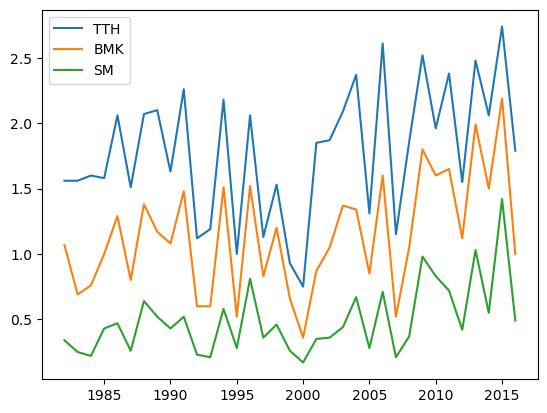

In [21]:
TreeR.plot()

In [24]:
TreeR.to_excel('TreeRegions_1982_2016.xlsx',index=True)

In [8]:
fig = go.Figure()
#Layout Setting
layout = go.Layout(
title=dict(text = "wheat yield 1982 - 2016",x=0.5,y=0.90),
title_font_size=24,
title_font_color='#9ca4cf',
xaxis=dict(
title = 'Year',
showgrid=False, # Hide Gridlines
showline=True, # Show X-Axis
linecolor='black', # Color of X-axis
tickfont_color='black', #Color of ticks
showticklabels=True, #Show X labels
dtick=5,
ticks='outside',
tickcolor='black',
),
yaxis=dict(
title = 'Yield(kg/ha)',
showgrid=False,
showline=True,
linecolor='black',
tickfont_color='black',
showticklabels=True,
ticks='outside',
tickcolor='black',
),
paper_bgcolor='white',
plot_bgcolor='white',
hovermode='closest',

)

fig = go.Figure(layout=layout)
#

fig.add_trace(go.Scatter(y = all['Rabat Sale Kenitra']['AY']* 1000,x = all.index,
                                    name = 'Rabat Sale Kenitra',mode='lines+markers', line_color='#000000'))
fig.add_trace(go.Scatter(y = all['Fes Meknes']['AY'] * 1000,x = all.index,
                                    name = 'Fes Meknes',mode='lines+markers', line_color='#808000'))
fig.add_trace(go.Scatter(y = all['Tanger Tetouan Al Hoceima']['AY']* 1000,x = all.index,
                                    name = 'Tanger Tetouan Al Hoceima',mode='lines+markers', line_color='#a9a9a9'))
fig.add_trace(go.Scatter(y =all['Beni Mellal Khenifra']['AY']* 1000,x = all.index,
                                    name = 'Beni Mellal Khenifra',mode='lines+markers', line_color='navy'))
fig.add_trace(go.Scatter(y = all['Casablanca Settat']['AY']* 1000,x = all.index,
                                    name = 'Casablanca Settat',mode='lines+markers', line_color='#00ff00'))
fig.add_trace(go.Scatter(y = all['Morocco']['AY']* 1000,x = all.index,
                                    name = 'Morocco',mode='lines+markers', line_color='#e6194B'))
fig.add_trace(go.Scatter(y = all['Marrakech Safi']['AY'] * 1000,x = all.index,
                                    name = 'Marrakech Safi ',mode='lines+markers', line_color='#aaffc3'))
fig.add_trace(go.Scatter(y = all['Draa Tafilalet']['AY']* 1000 ,x = all.index,
                                    name = 'Draa Tafilalet',mode='lines+markers', line_color='#ffe119'))
fig.add_trace(go.Scatter(y = all['Oriental']['AY'] * 1000,x = all.index,
                                    name = 'Oriental',mode='lines+markers', line_color='#f58231'))
fig.add_trace(go.Scatter(y = all['Souss Massa']['AY'] * 1000,x = all.index,
                                    name = 'Souss Massa',mode='lines+markers', line_color='#3cb44b'))
iplot(fig)

In [6]:
fig = go.Figure()
#Layout Setting
layout = go.Layout(
title=dict(text = "wheat yield 1982 - 2016",x=0.5,y=0.90),
title_font_size=24,
title_font_color='#9ca4cf',
xaxis=dict(
title = 'Year',
showgrid=False, # Hide Gridlines
showline=True, # Show X-Axis
linecolor='black', # Color of X-axis
tickfont_color='black', #Color of ticks
showticklabels=True, #Show X labels
dtick=5,
ticks='outside',
tickcolor='black',
),
yaxis=dict(
title = 'Yield Gap(kg/ha)',
showgrid=False,
showline=True,
linecolor='black',
tickfont_color='black',
showticklabels=True,
ticks='outside',
tickcolor='black',
),
paper_bgcolor='white',
plot_bgcolor='white',
hovermode='closest',

)

fig = go.Figure(layout=layout)
#


fig.add_trace(go.Scatter(y = all['Tanger Tetouan Al Hoceima']['YG (Mueller)']* 1000,x = all.index,
                                    name = 'Tanger Tetouan Al Hoceima',mode='lines+markers', line_color='#00ff00'))
fig.add_trace(go.Scatter(y =all['Beni Mellal Khenifra']['YG (Mueller)']* 1000,x = all.index,
                                    name = 'Beni Mellal Khenifra',mode='lines+markers', line_color='#f58231'))

#fig.add_trace(go.Scatter(y = all['Morocco']['YG (Mueller)']* 1000,x = all.index,
 #                                   name = 'Morocco',mode='lines+markers', line_color='#aaffc3'))

fig.add_trace(go.Scatter(y = all['Souss Massa']['YG (Mueller)'] * 1000,x = all.index,
                                    name = 'Souss Massa',mode='lines+markers', line_color='#ffe119'))
iplot(fig)

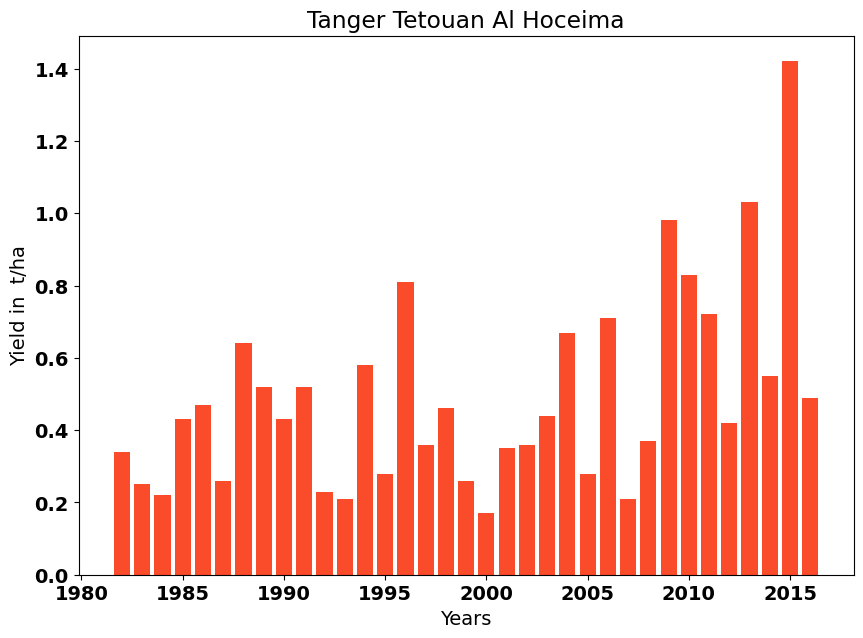

In [12]:
# To display the data in the chart
#style the font size
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 14}
plt.rc('font', **font)

#chart Title
plt.title('Tanger Tetouan Al Hoceima')

#chart lable for x axis
plt.xlabel('Years')

#chart lable for y axis
plt.ylabel('Yield in  t/ha')

#chart size and data assign
plt.bar(  all.index,all['Souss Massa']['AY'], color='#fa4b2a')
plt.rcParams["figure.figsize"] = (10,7)

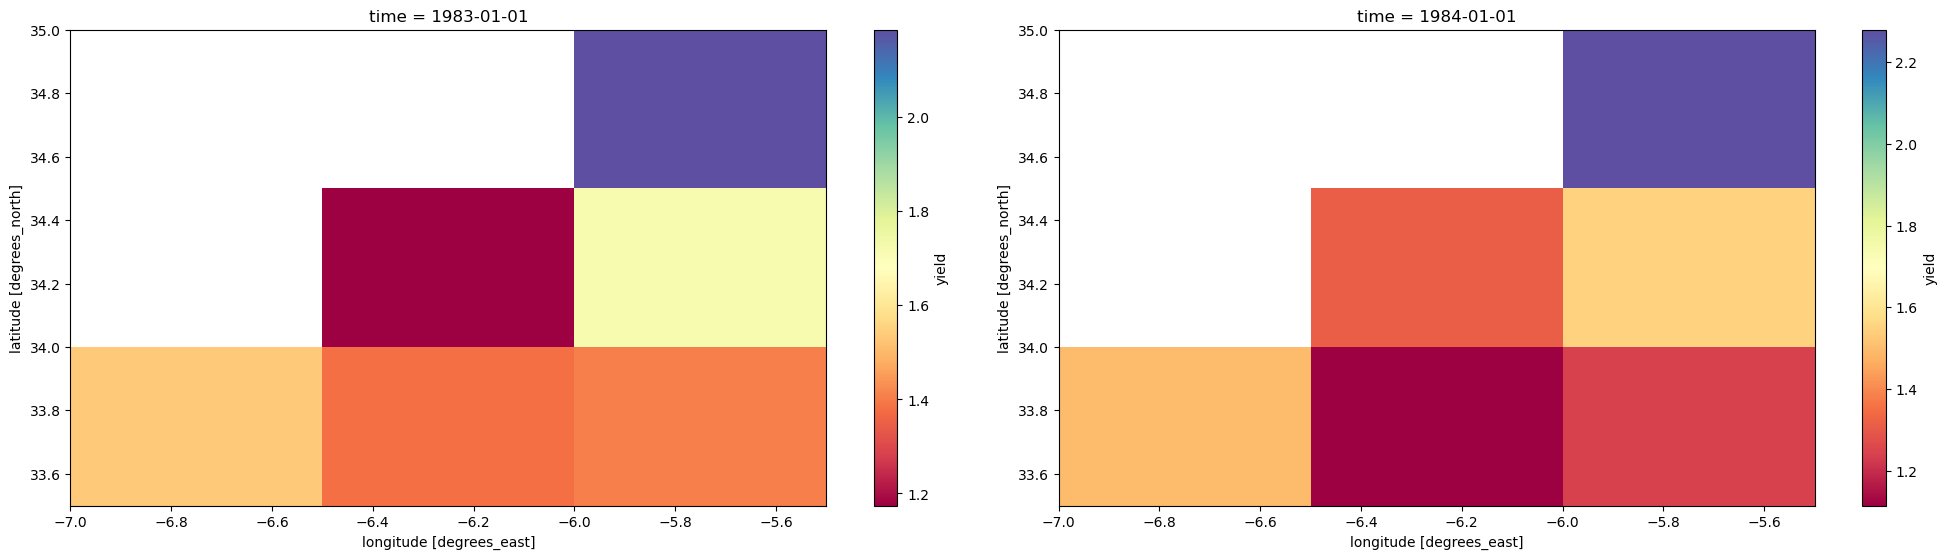

In [127]:
plt.figure(figsize=(40, 48))
for i in range(1, 3):
    ax = plt.subplot(9, 4, i)
    o['yield'][i].plot(x='longitude', y='latitude', cmap='Spectral', ax=ax)
plt.tight_layout()

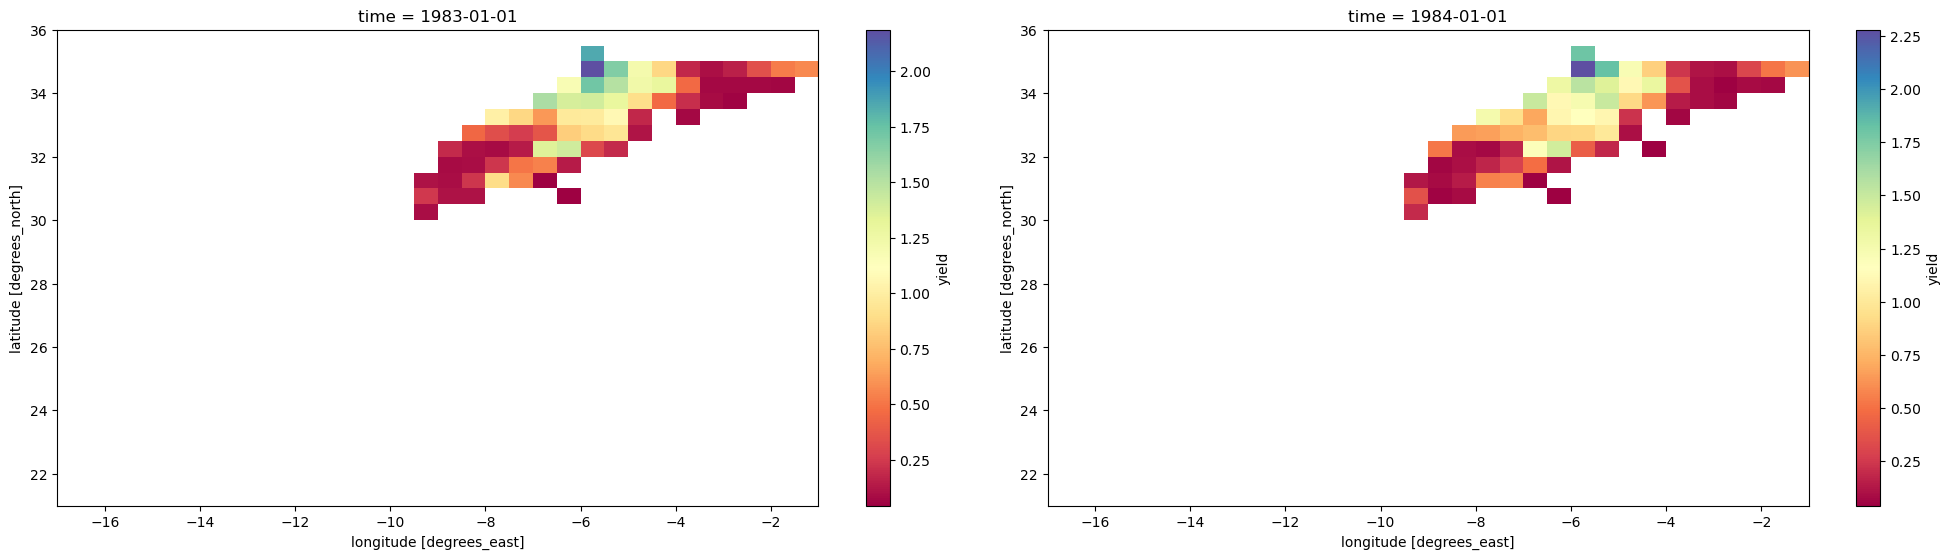

In [129]:
plt.figure(figsize=(40, 48))
for i in range(1, 3):
    ax = plt.subplot(9, 4, i)
    m['yield'][i].plot(x='longitude', y='latitude', cmap='Spectral', ax=ax)
plt.tight_layout()

### Oriental SRK

In [113]:
import warnings
warnings.filterwarnings('ignore')

In [13]:
def processing(file):
 ds = xr.open_dataset(file)
 df = ds.to_dataframe()
 m = df['wheat.yield.t.ha'].mean()
 return m

In [118]:
df = pd.DataFrame()

In [153]:
a  = processing("wheat/RabatSaleKenitra/yield_2017.nc")
df =                       df.append({'Year':'2016','Yield t/ha':a}, ignore_index=True)

In [154]:
df = df.set_index('Year')

In [155]:
df 

,Yield t/ha
Year,
1982,1.640287
1983,1.328840
1984,1.327043
1985,1.424948
1986,2.089018
1987,1.340491
1988,2.065275
1989,1.737319
1990,1.588066


In [156]:
df.to_csv('RabatSaleKenitra.csv', sep=',')

In [157]:
wbenimkh = pd.read_csv('RabatSaleKenitra.csv')
wbenimkh = wbenimkh.set_index('Year')

In [158]:
#wbenimkh = wbenimkh.set_index('Year')
wbenimkh = wbenimkh.rename(columns={"Yield t/ha": "AY"}, errors="raise")
#wbenimkh = wbenimkh.drop('Unnamed: 0',axis=1) 

In [159]:
wbenimkh.head()

,AY
Year,
1982,1.640287
1983,1.328840
1984,1.327043
1985,1.424948
1986,2.089018


In [160]:
wbenimkh['PY (max)'] = np.max(wbenimkh['AY'])
wbenimkh['PY (Mueller)'] = 4.1

In [161]:
wbenimkh['AY'] = round(wbenimkh['AY'], 2)
wbenimkh['PY (max)'] = round(wbenimkh['PY (max)'], 2)
wbenimkh['PY (Mueller)'] = round(wbenimkh['PY (Mueller)'], 2)

In [162]:
wbenimkh['YG (max)'] = wbenimkh['PY (max)'] - wbenimkh['AY']
wbenimkh['YG (Mueller)'] = wbenimkh['PY (Mueller)'] - wbenimkh['AY']

<AxesSubplot:xlabel='Year'>

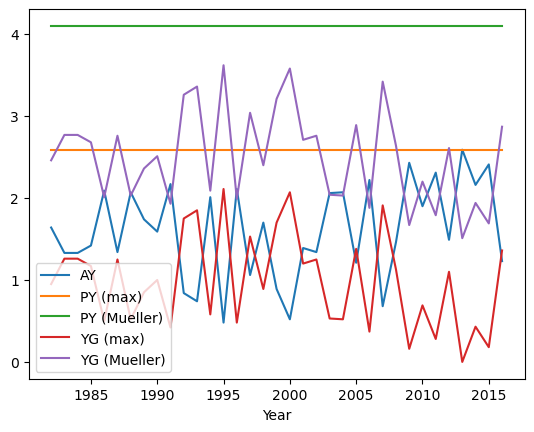

In [163]:
wbenimkh.plot()

In [6]:
df = all['Tanger Tetouan Al Hoceima']

In [11]:
df.to_excel('TangerTetouanAlHoceima_1982_2016.xlsx',index=True)

In [33]:
all.head(3)

Morocco                                              \
Year      AY PY (max) PY (Mueller) YG (max) YG (Mueller)   
1982    0.78     1.97          4.1     1.19         3.32   
1983    0.60     1.97          4.1     1.37         3.50   
1984    0.62     1.97          4.1     1.35         3.48   

     Tanger Tetouan Al Hoceima                                              \
Year                        AY PY (max) PY (Mueller) YG (max) YG (Mueller)   
1982                      1.56     2.74          4.1     1.18         2.54   
1983                      1.56     2.74          4.1     1.18         2.54   
1984                      1.60     2.74          4.1     1.14         2.50   

      ... Draa Tafilalet              Souss Massa                        \
Year  ...       YG (max) YG (Mueller)          AY PY (max) PY (Mueller)   
1982  ...           1.33         3.26        0.34     1.42          4.1   
1983  ...           1.62         3.55        0.25     1.42          4.1   
1984  ...           1.59         3.52        0.22     1.42          4.1   

                           Guelmim Oued Noun Laayoune Sakia ElHamra  \
Year YG (max) YG (Mueller)        Yield t/ha             Yield t/ha   
1982     1.08         3.76               NaN                    NaN   
1983     1.17         3.85               NaN                    NaN   
1984     1.20         3.88               NaN                    NaN   

     Eddakhla Oued Eddahab  
Year            Yield t/ha  
1982                   NaN  
1983                   NaN  
1984                   NaN  

[3 rows x 53 columns]

<center><h1 style='color:aqua'>Conversion</h1></center>

In [1]:
import geopandas

In [14]:
myshpfile = geopandas.read_file('shapfiles/Maroc/Maroc.shp')
myshpfile.to_file('shapfiles/Maroc/Maroc.shp.geojson', driver='GeoJSON')

<center><h1 style='color:aqua'>CHIRPS</h1></center>

In [5]:
%matplotlib inline
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
tth = xr.open_dataset('Precipitation/netcdf/TangerTetouanAlHoceima.nc')
bmk = xr.open_dataset('Precipitation/netcdf/BeniMellalKhnifra.nc')
sm = xr.open_dataset('Precipitation/netcdf/SoussMassa.nc')
m = xr.open_dataset('Precipitation/netcdf/maroc_1981_2016.nc')

c:\Users\Lahcen.OUSAYD\Anaconda3\lib\site-packages\ecmwflibs\__init__.py:83: UserWarning:

DLL load failed while importing _ecmwflibs: The specified procedure could not be found.

c:\Users\Lahcen.OUSAYD\Anaconda3\lib\site-packages\xarray\backends\plugins.py:71: RuntimeWarning:

Engine 'cfgrib' loading failed:
ecCodes library not found using ['eccodes', 'libeccodes.so', 'libeccodes']



In [7]:
m

<xarray.Dataset>
Dimensions:               (time: 13149, longitude: 328, latitude: 311)
Coordinates:
  * time                  (time) datetime64[ns] 1981-01-01 ... 2016-12-31
  * longitude             (longitude) float64 -17.32 -17.27 ... -1.025 -0.975
  * latitude              (latitude) float64 20.57 20.62 20.67 ... 36.02 36.07
Data variables:
    precipitation_amount  (time, latitude, longitude) float32 ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Thu Jan 19 15:29:47 2023: cdo mergetime 1981_1985.nc 1986_1...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [8]:
tth = tth.resample(time = 'm', ).sum()
bmk = bmk.resample(time = 'm', ).sum()
sm = sm.resample(time = 'm', ).sum()
m = m.resample(time= 'm').sum()

In [9]:
m.time

<xarray.DataArray 'time' (time: 432)>
array(['1981-01-31T00:00:00.000000000', '1981-02-28T00:00:00.000000000',
       '1981-03-31T00:00:00.000000000', ..., '2016-10-31T00:00:00.000000000',
       '2016-11-30T00:00:00.000000000', '2016-12-31T00:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 1981-01-31 1981-02-28 ... 2016-12-31

In [10]:
import calendar # We'll use this library to easily add month name to subplot titles.
# First, We will develop a land mask data array that we can use to mask out the nan values:
tthMask = tth.precipitation_amount.sum(dim='time')>0
bmkMask = bmk.precipitation_amount.sum(dim='time')>0
smMask = sm.precipitation_amount.sum(dim='time')>0
mMask = m.precipitation_amount.sum(dim='time')>0

In [11]:
ts = pd.to_datetime(str(m.time.values[:12][3]))
import pandas as pd 
#ts = pd.to_datetime(str(date)) 
ts.strftime('%Y')

'1981'

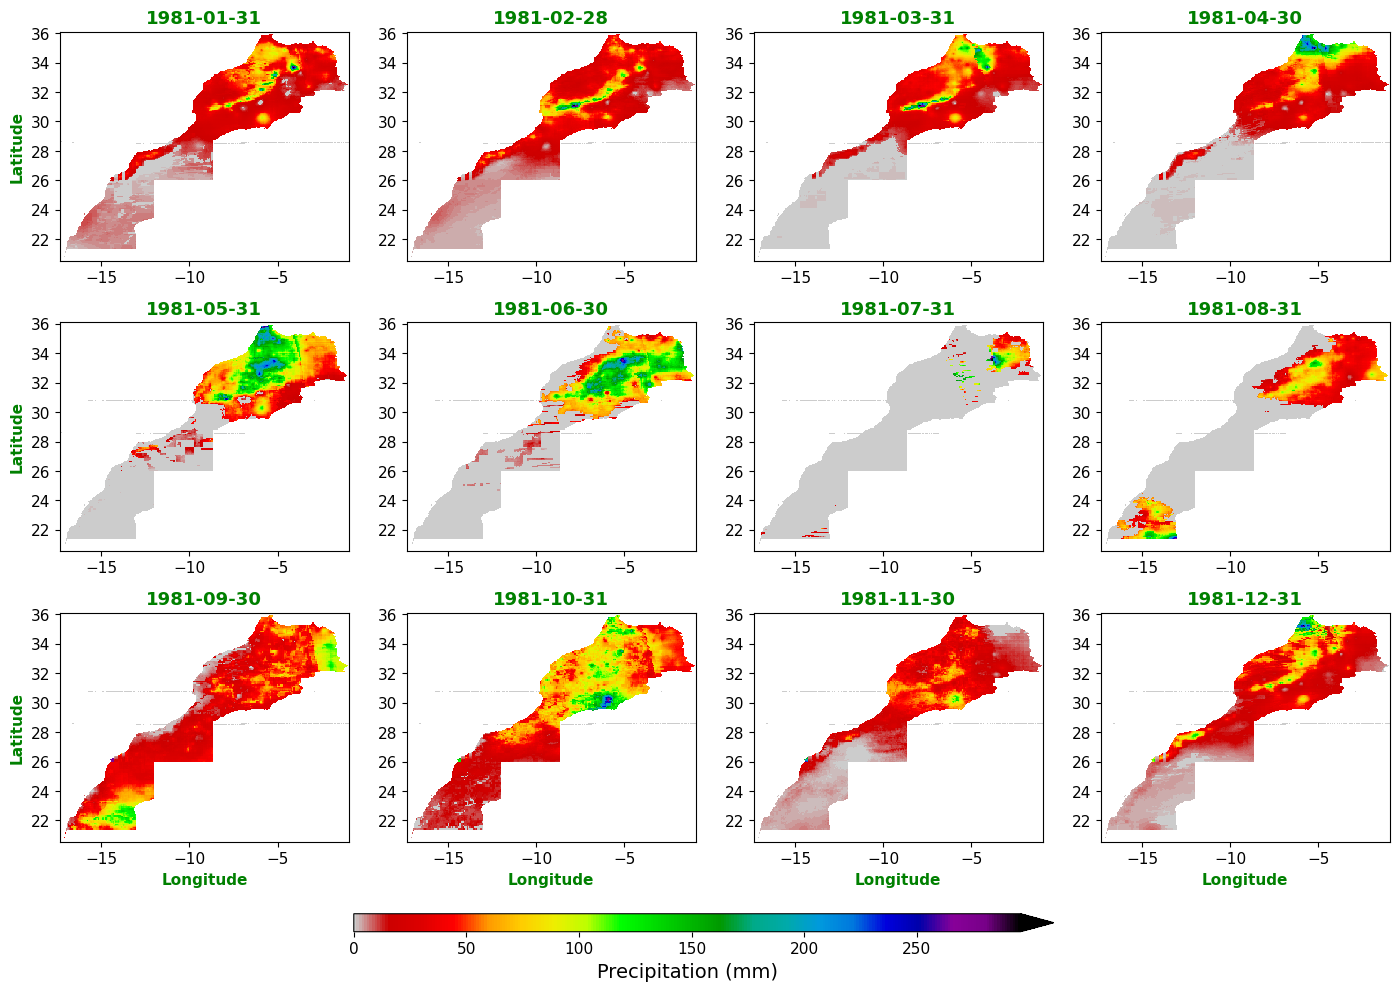

In [12]:
fig = plt.figure(figsize=[14,10], facecolor='w')
plt.subplots_adjust(bottom=0.15, top=0.96, left=0.04, right=0.99, 
                    wspace=0.2, hspace=0.27) # wspace and hspace adjust the horizontal and vertical spaces, respectively.
nrows = 3
ncols = 4
for i in range(1, 13):
    plt.subplot(nrows, ncols, i)
    dataplot = m.precipitation_amount[i-1, :, :].where(mMask) # Remember that in Python, the data index starts at 0, but the subplot index start at 1.
    p = plt.pcolormesh(m.longitude, m.latitude, dataplot,
                     #vmax = 300, vmin = 0,
                     cmap = 'nipy_spectral_r',shading='auto'
                   ) 
    #plt.xlim([233,295])
    #plt.ylim([25,50])
    plt.title(pd.to_datetime(str(m.time.values[:][i-1])).strftime('%Y-%m-%d'), fontsize = 13, 
              fontweight = 'bold', color = 'g')
    plt.xticks(fontsize = 11)
    plt.yticks(fontsize = 11)
    if i % ncols == 1: # Add ylabel for the very left subplots
        plt.ylabel('Latitude', fontsize = 11, fontweight = 'bold',color = 'g')
    if i > ncols*(nrows-1): # Add xlabel for the bottom row subplots
        plt.xlabel('Longitude', fontsize = 11, fontweight = 'bold',color = 'g')
    
# Add a colorbar at the bottom:
cax = fig.add_axes([0.25, 0.06, 0.5, 0.018])
cb = plt.colorbar(cax=cax, orientation='horizontal', extend = 'max',)
cb.ax.tick_params(labelsize=11)
cb.set_label(label='Precipitation (mm)', color = 'k', size=14)

# Now we can save a high resolution (300dpi) version of the figure:
#plt.savefig('Fig_prec_cpc_mon_2012.png', format = 'png', dpi = 300)

In [13]:
monthly_ds_loc=tth.sel(longitude= -4.5,latitude=35.,method='nearest')

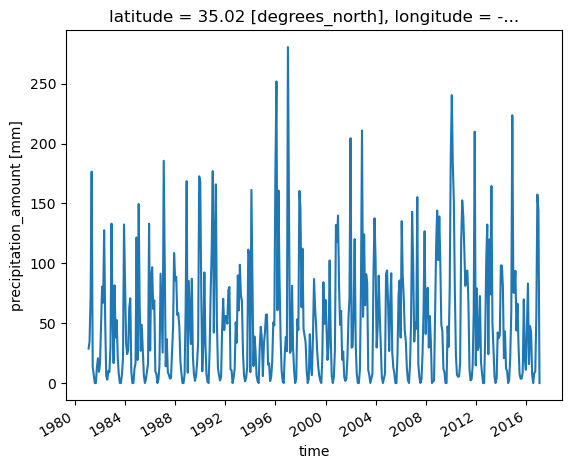

In [14]:
monthly_ds_loc['precipitation_amount'].plot() # plot montlhy cloud fraction data

In [15]:
ds = m

In [16]:
year_81_82 = ds.sel(time=slice('1981-10-30', '1982-05-31'))
landmask1 = year_81_82.precipitation_amount.mean(dim='time')>0
S_81_82 = year_81_82.where(landmask1)

year_82_83 = ds.sel(time=slice('1982-09-30', '1983-05-31'))
landmask2 = year_82_83.precipitation_amount.sum(dim='time')>0
S_82_83 = year_82_83.where(landmask2)

year_83_84 = ds.sel(time=slice('1983-09-30', '1984-05-31'))
landmask3 = year_83_84.precipitation_amount.sum(dim='time')>0
S_83_84 = year_83_84 .where(landmask3)

year_84_85  = ds.sel(time=slice('1984-09-30', '1985-05-31'))
landmask4 = year_84_85.precipitation_amount.sum(dim='time')>0
S_84_85 = year_84_85.where(landmask4)

year_85_86 = ds.sel(time=slice('1985-09-30', '1986-05-31'))
landmask5 = year_85_86.precipitation_amount.sum(dim='time')>0
S_85_86 = year_85_86.where(landmask5)

year_86_87 = ds.sel(time=slice('1986-09-30', '1987-05-30'))
landmask6 = year_86_87.precipitation_amount.sum(dim='time')>0
S_86_87 = year_86_87.where(landmask6)

year_87_88 = ds.sel(time=slice('1987-09-30', '1988-05-31'))
landmask7 = year_87_88.precipitation_amount.sum(dim='time')>0
S_87_88 = year_87_88.where(landmask7)

year_88_89 = ds.sel(time=slice('1988-09-30', '1989-05-31'))
landmask8 = year_88_89.precipitation_amount.sum(dim='time')>0
S_88_89 = year_88_89.where(landmask8)

year_89_90 = ds.sel(time=slice('1989-09-30', '1990-05-31'))
landmask9 = year_89_90.precipitation_amount.sum(dim='time')>0
S_89_90 = year_89_90.where(landmask9)

year_90_91 = ds.sel(time=slice('1990-09-30', '1991-05-31'))
landmask10 = year_90_91.precipitation_amount.sum(dim='time')>0
S_90_91 = year_90_91.where(landmask10)

year_91_92 = ds.sel(time=slice('1991-09-30', '1992-05-31'))
landmask11 = year_91_92.precipitation_amount.sum(dim='time')>0
S_91_92 = year_91_92.where(landmask11)

year_92_93 = ds.sel(time=slice('1992-09-30', '1993-05-31'))
landmask12 = year_92_93.precipitation_amount.sum(dim='time')>0
S_92_93 = year_92_93.where(landmask12)

year_93_94 = ds.sel(time=slice('1993-09-30', '1994-05-31'))
landmask13 = year_93_94.precipitation_amount.sum(dim='time')>0
S_93_94 = year_93_94.where(landmask13)

year_94_95 = ds.sel(time=slice('1994-09-30', '1995-05-31'))
landmask14 = year_94_95.precipitation_amount.sum(dim='time')>0
S_94_95 = year_94_95.where(landmask14)

year_95_96 = ds.sel(time=slice('1995-09-30', '1996-05-31'))
landmask15 = year_95_96.precipitation_amount.sum(dim='time')>0
S_95_96 = year_95_96.where(landmask15)

year_96_97 = ds.sel(time=slice('1996-09-30', '1997-05-31'))
landmask16 = year_96_97.precipitation_amount.sum(dim='time')>0
S_96_97 = year_96_97.where(landmask16)

year_97_98 = ds.sel(time=slice('1997-09-30', '1998-05-31'))
landmask17 = year_97_98.precipitation_amount.sum(dim='time')>0
S_97_98 = year_97_98.where(landmask17)

year_98_99 = ds.sel(time=slice('1998-09-30', '1999-05-31'))
landmask18 = year_98_99.precipitation_amount.sum(dim='time')>0
S_98_99 = year_98_99.where(landmask18)

year_99_00 = ds.sel(time=slice('1999-09-30', '2000-05-31'))
landmask19 = year_99_00.precipitation_amount.sum(dim='time')>0
S_99_00 = year_99_00.where(landmask19)

year_00_01 = ds.sel(time=slice('2000-09-30', '2001-05-31'))
landmask20 = year_00_01.precipitation_amount.sum(dim='time')>0
S_00_01 = year_00_01.where(landmask20)

year_01_02 = ds.sel(time=slice('2001-09-30', '2002-05-31'))
landmask21 = year_01_02.precipitation_amount.sum(dim='time')>0
S_01_02 = year_01_02.where(landmask21)

year_02_03 = ds.sel(time=slice('2002-09-30', '2003-05-31'))
landmask22 = year_02_03.precipitation_amount.sum(dim='time')>0
S_02_03 = year_02_03.where(landmask22)

year_03_04 = ds.sel(time=slice('2003-09-30', '2004-05-31'))
landmask23 = year_03_04 .precipitation_amount.sum(dim='time')>0
S_03_04  = year_03_04 .where(landmask23)

year_04_05  = ds.sel(time=slice('2004-09-30', '2005-05-31'))
landmask24 = year_04_05.precipitation_amount.sum(dim='time')>0
S_04_05 = year_04_05.where(landmask24)

year_05_06 = ds.sel(time=slice('2005-09-30', '2006-05-31'))
landmask25 = year_05_06.precipitation_amount.sum(dim='time')>0
S_05_06 = year_05_06.where(landmask25)

year_06_07 = ds.sel(time=slice('2006-09-30', '2007-05-31'))
landmask26= year_06_07.precipitation_amount.sum(dim='time')>0
S_06_07 = year_06_07.where(landmask26)

year_07_08 = ds.sel(time=slice('2007-09-30', '2008-05-31'))
landmask27 = year_07_08.precipitation_amount.sum(dim='time')>0
S_07_08= year_07_08.where(landmask27)

year_08_09 = ds.sel(time=slice('2008-09-30', '2009-05-31'))
landmask28 = year_08_09.precipitation_amount.sum(dim='time')>0
S_08_09 = year_08_09.where(landmask28)

year_09_10 = ds.sel(time=slice('2009-10-30', '2010-05-31'))
landmask29 = year_09_10.precipitation_amount.sum(dim='time')>0
S_09_10 = year_09_10.where(landmask29)

year_10_11 = ds.sel(time=slice('2010-09-30', '2011-05-31'))
landmask30 = year_10_11.precipitation_amount.sum(dim='time')>0
S_10_11 = year_10_11.where(landmask30)

year_11_12 = ds.sel(time=slice('2011-09-30', '2012-05-31'))
landmask31 = year_11_12.precipitation_amount.sum(dim='time')>0
S_11_12 = year_11_12.where(landmask31)

year_12_13 = ds.sel(time=slice('2012-09-30', '2013-05-31'))
landmask32 = year_12_13.precipitation_amount.sum(dim='time')>0
S_12_13 = year_12_13.where(landmask32)

year_13_14 = ds.sel(time=slice('2013-09-30', '2014-05-31'))
landmask33 = year_13_14.precipitation_amount.sum(dim='time')>0
S_13_14 = year_13_14.where(landmask33)

year_14_15 = ds.sel(time=slice('2014-09-30', '2015-05-31'))
landmask34 = year_14_15.precipitation_amount.sum(dim='time')>0
S_14_15 = year_14_15.where(landmask34)

year_15_16 = ds.sel(time=slice('2015-09-30', '2016-05-31'))
landmask35 = year_15_16.precipitation_amount.sum(dim='time')>0
S_15_16 = year_15_16.where(landmask35)


In [18]:
S_81_82.time

<xarray.DataArray 'time' (time: 8)>
array(['1981-10-31T00:00:00.000000000', '1981-11-30T00:00:00.000000000',
       '1981-12-31T00:00:00.000000000', '1982-01-31T00:00:00.000000000',
       '1982-02-28T00:00:00.000000000', '1982-03-31T00:00:00.000000000',
       '1982-04-30T00:00:00.000000000', '1982-05-31T00:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 1981-10-31 1981-11-30 ... 1982-05-31

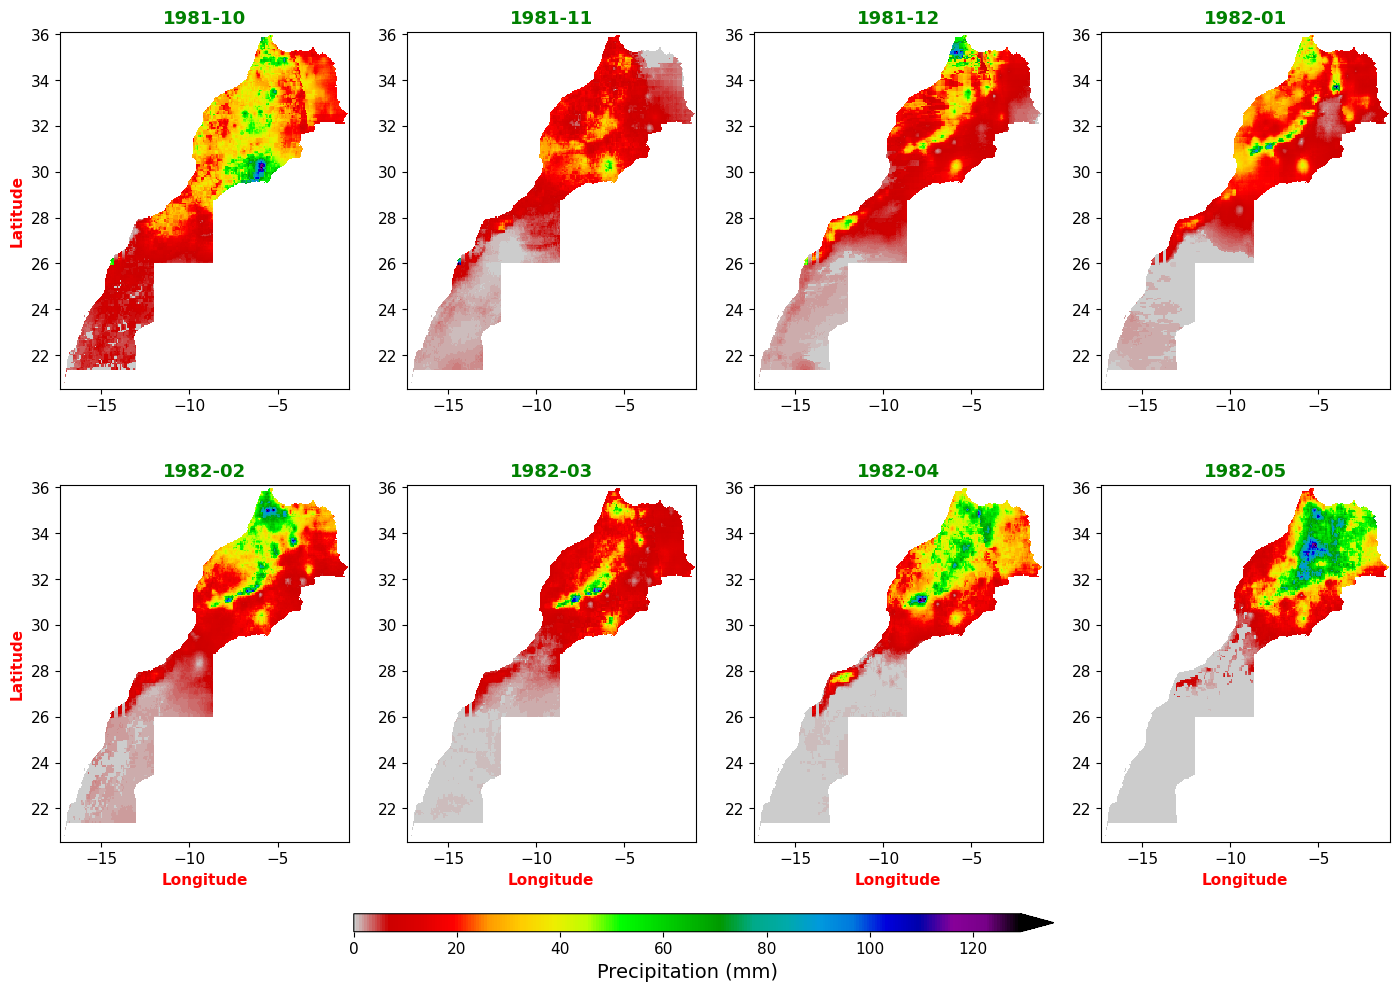

In [19]:
fig = plt.figure(figsize=[14,10], facecolor='w')
plt.subplots_adjust(bottom=0.15, top=0.96, left=0.04, right=0.99, 
                    wspace=0.2, hspace=0.27) # wspace and hspace adjust the horizontal and vertical spaces, respectively.
nrows = 2
ncols = 4
for i in range(1, 9):
    plt.subplot(nrows, ncols, i)
    dataplot = S_81_82.precipitation_amount[i-1, :, :].where(landmask29) # Remember that in Python, the data index starts at 0, but the subplot index start at 1.
    p = plt.pcolormesh(ds.longitude, ds.latitude, dataplot,
                     #vmax = 80, vmin = 0,
                     cmap = 'nipy_spectral_r',shading='auto'
                   ) 
    #plt.xlim([233,295])
    #plt.ylim([25,50])
    plt.title(pd.to_datetime(str(S_81_82.time.values[i-1])).strftime('%Y-%m'), fontsize = 13, 
              fontweight = 'bold', color = 'g')
    plt.xticks(fontsize = 11)
    plt.yticks(fontsize = 11)
    if i % ncols == 1: # Add ylabel for the very left subplots
        plt.ylabel('Latitude', fontsize = 11, fontweight = 'bold',color = 'r')
    if i > ncols*(nrows-1): # Add xlabel for the bottom row subplots
        plt.xlabel('Longitude', fontsize = 11, fontweight = 'bold',color = 'r')
    
# Add a colorbar at the bottom:
cax = fig.add_axes([0.25, 0.06, 0.5, 0.018])
cb = plt.colorbar(cax=cax, orientation='horizontal', extend = 'max',)
cb.ax.tick_params(labelsize=11)
cb.set_label(label='Precipitation (mm)', color = 'k', size=14)

# Now we can save a high resolution (300dpi) version of the figure:
#plt.savefig('Fig_prec_cpc_mon_2012.png', format = 'png', dpi = 300)

In [1040]:
a = 0
for i in range(8):
        a += S_81_82.precipitation_amount[:][i]
        print(a.max())
        a['time'] = np.datetime64(pd.to_datetime(str(S_98_99.time.values[i-1])).strftime('%Y'))
#a.to_netcdf('Precipitation/maroc/S_2015_2016.nc')

<xarray.DataArray 'precipitation_amount' ()>
array(69.78713989)
Coordinates:
    time     datetime64[ns] 1981-10-31
<xarray.DataArray 'precipitation_amount' ()>
array(251.00640869)
Coordinates:
    time     datetime64[ns] 1999-01-01
<xarray.DataArray 'precipitation_amount' ()>
array(363.29125977)
Coordinates:
    time     datetime64[ns] 1998-01-01
<xarray.DataArray 'precipitation_amount' ()>
array(456.43103027)
Coordinates:
    time     datetime64[ns] 1998-01-01
<xarray.DataArray 'precipitation_amount' ()>
array(623.08459473)
Coordinates:
    time     datetime64[ns] 1998-01-01
<xarray.DataArray 'precipitation_amount' ()>
array(838.85974121)
Coordinates:
    time     datetime64[ns] 1998-01-01
<xarray.DataArray 'precipitation_amount' ()>
array(1057.9074707)
Coordinates:
    time     datetime64[ns] 1999-01-01
<xarray.DataArray 'precipitation_amount' ()>
array(1108.05725098)
Coordinates:
    time     datetime64[ns] 1999-01-01


In [1001]:
a.max()

<xarray.DataArray 'precipitation_amount' ()>
array(7.20844941e+31)
Coordinates:
    time     datetime64[ns] 1994-01-01

<center><h1 style='color:aqua'>Yearly AVG</h1></center>

In [12]:
ds82  = xr.open_dataset('Precipitation/maroc/S_1981_1982.nc')
ds83  = xr.open_dataset('Precipitation/maroc/S_1982_1983.nc')
ds84  = xr.open_dataset('Precipitation/maroc/S_1983_1984.nc')
ds85  = xr.open_dataset('Precipitation/maroc/S_1984_1985.nc')
ds86  = xr.open_dataset('Precipitation/maroc/S_1985_1986.nc')
ds87  = xr.open_dataset('Precipitation/maroc/S_1986_1987.nc')
ds88  = xr.open_dataset('Precipitation/maroc/S_1987_1988.nc')
ds89  = xr.open_dataset('Precipitation/maroc/S_1988_1989.nc')

In [13]:
ds90  = xr.open_dataset('Precipitation/maroc/S_1989_1990.nc')
ds91  = xr.open_dataset('Precipitation/maroc/S_1990_1991.nc')
ds92  = xr.open_dataset('Precipitation/maroc/S_1991_1992.nc')
ds93  = xr.open_dataset('Precipitation/maroc/S_1992_1993.nc')
ds94  = xr.open_dataset('Precipitation/maroc/S_1993_1994.nc')
ds95  = xr.open_dataset('Precipitation/maroc/S_1994_1995.nc')
ds96  = xr.open_dataset('Precipitation/maroc/S_1995_1996.nc')
ds97  = xr.open_dataset('Precipitation/maroc/S_1996_1997.nc')

In [14]:
ds95.precipitation_amount.max()

<xarray.DataArray 'precipitation_amount' ()>
array(993.09527588)
Coordinates:
    time     datetime64[ns] ...

In [15]:
ds98  = xr.open_dataset('Precipitation/maroc/S_1997_1998.nc')
ds99  = xr.open_dataset('Precipitation/maroc/S_1998_1999.nc')
ds00  = xr.open_dataset('Precipitation/maroc/S_1999_2000.nc')
ds01  = xr.open_dataset('Precipitation/maroc/S_2000_2001.nc')
ds02  = xr.open_dataset('Precipitation/maroc/S_2001_2002.nc')
ds03  = xr.open_dataset('Precipitation/maroc/S_2002_2003.nc')
ds04  = xr.open_dataset('Precipitation/maroc/S_2003_2004.nc')
ds05  = xr.open_dataset('Precipitation/maroc/S_2004_2005.nc')

In [16]:
ds06  = xr.open_dataset('Precipitation/maroc/S_2005_2006.nc')
ds07  = xr.open_dataset('Precipitation/maroc/S_2006_2007.nc')
ds08  = xr.open_dataset('Precipitation/maroc/S_2007_2008.nc')
ds09  = xr.open_dataset('Precipitation/maroc/S_2008_2009.nc')
ds10  = xr.open_dataset('Precipitation/maroc/S_2009_2010.nc')
ds11  = xr.open_dataset('Precipitation/maroc/S_2010_2011.nc')
ds12  = xr.open_dataset('Precipitation/maroc/S_2011_2012.nc')
ds13  = xr.open_dataset('Precipitation/maroc/S_2012_2013.nc')
ds14  = xr.open_dataset('Precipitation/maroc/S_2013_2014.nc')
ds15  = xr.open_dataset('Precipitation/maroc/S_2014_2015.nc')
ds16  = xr.open_dataset('Precipitation/maroc/S_2015_2016.nc')

In [21]:
ds_m = xr.combine_nested([ds82,ds83,ds84,ds85,ds86,ds87,ds88,ds89,ds90,ds91,ds92,ds93,ds94,ds95,ds96,ds97,
                         ds98,ds99,ds00,ds01,ds02,ds03,ds04,ds05,ds06,ds07,ds08,ds09,ds10,ds11,ds12,ds13,ds14,ds15,ds16], concat_dim=["time"])

In [24]:
ds_m = xr.open_dataset('Precipitation/maroc/Y_1981_2016.nc')

In [25]:
ds_m

<xarray.Dataset>
Dimensions:               (time: 35, longitude: 323, latitude: 297)
Coordinates:
  * time                  (time) datetime64[ns] 1982-01-01 ... 2016-01-01
  * longitude             (longitude) float64 -17.07 -17.02 ... -1.025 -0.975
  * latitude              (latitude) float64 21.12 21.17 21.22 ... 35.87 35.92
Data variables:
    precipitation_amount  (time, latitude, longitude) float32 ...

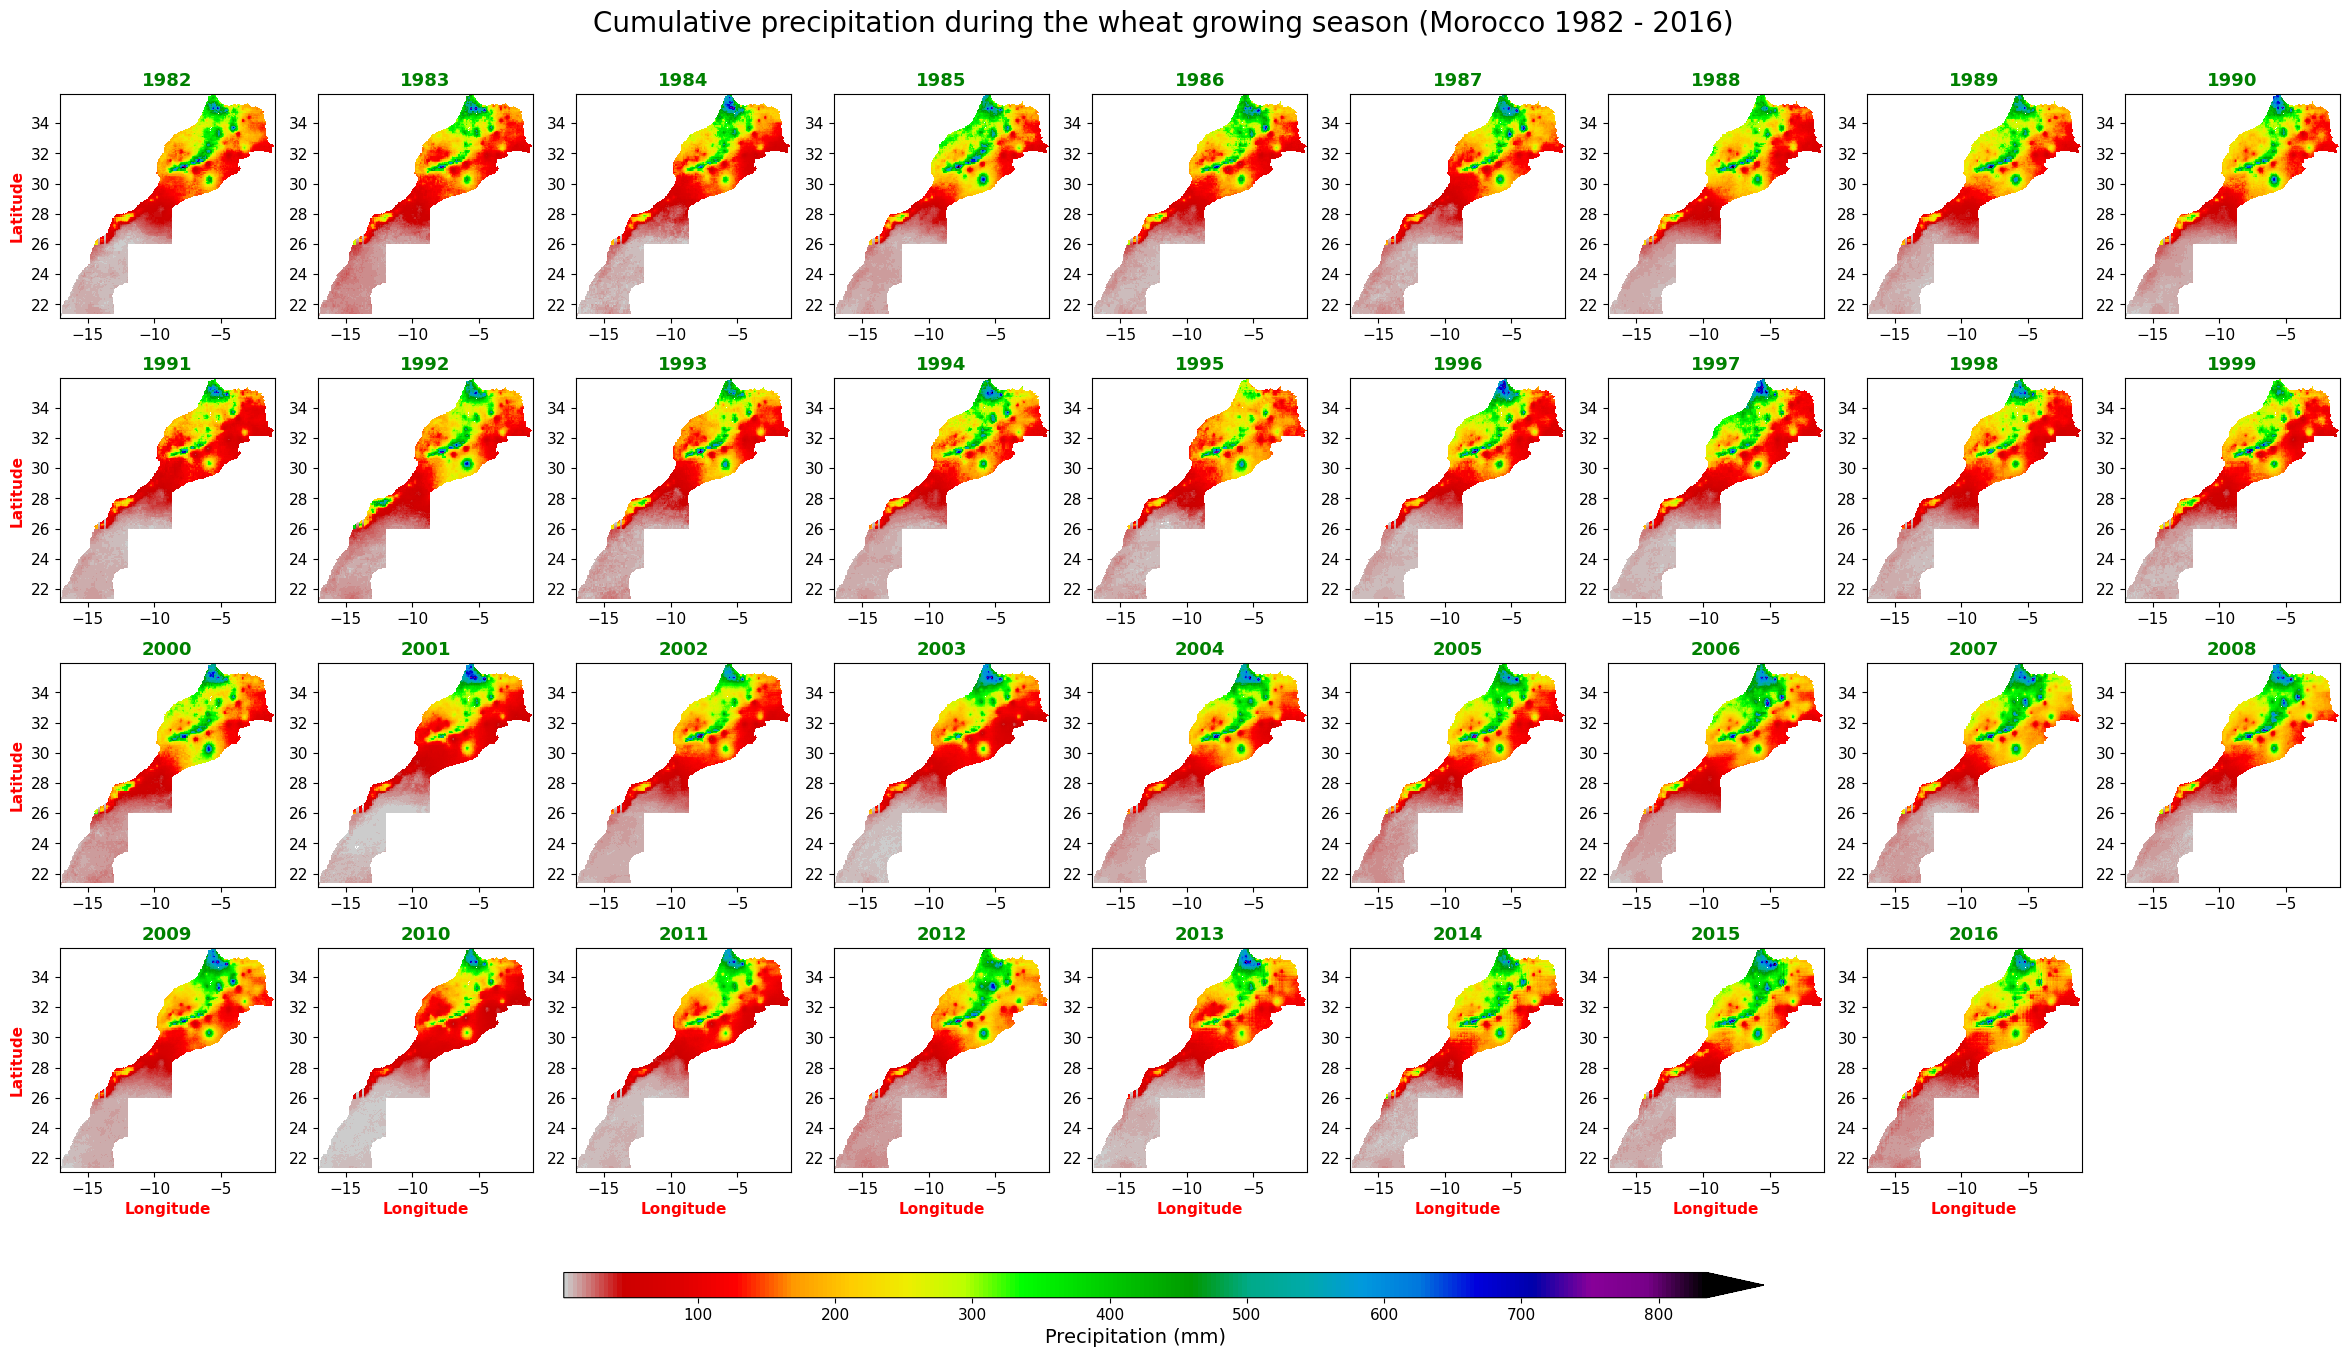

In [20]:
fig = plt.figure(figsize=[24,14], facecolor='w')
plt.subplots_adjust(bottom=0.15, top=0.96, left=0.04, right=0.99, 
                    wspace=0.2, hspace=0.27) # wspace and hspace adjust the horizontal and vertical spaces, respectively.
nrows = 4
ncols = 9
for i in range(1, 36):
    plt.subplot(nrows, ncols, i)
    dataplot = ds_m.precipitation_amount[i-1, :, :]# Remember that in Python, the data index starts at 0, but the subplot index start at 1.
    p = plt.pcolormesh(ds_m.longitude, ds_m.latitude, dataplot,
                     #vmax = 300, vmin = 0,
                     cmap = 'nipy_spectral_r',shading='auto'
                   ) 
    #plt.xlim([233,295])
    #plt.ylim([25,50])
    plt.title(pd.to_datetime(str(ds_m.time.values[i-1])).strftime('%Y'), fontsize = 13, 
              fontweight = 'bold', color = 'g')
    plt.xticks(fontsize = 11)
    plt.yticks(fontsize = 11)
    if i % ncols == 1: # Add ylabel for the very left subplots
        plt.ylabel('Latitude', fontsize = 11, fontweight = 'bold',color = 'r')
    if i > ncols*(nrows-1): # Add xlabel for the bottom row subplots
        plt.xlabel('Longitude', fontsize = 11, fontweight = 'bold',color = 'r')
    
# Add a colorbar at the bottom:
cax = fig.add_axes([0.25, 0.06, 0.5, 0.018])
cb = plt.colorbar(cax=cax, orientation='horizontal', extend = 'max',)
cb.ax.tick_params(labelsize=11)
cb.set_label(label='Precipitation (mm)', color = 'k', size=14)
fig.suptitle('Cumulative precipitation during the wheat growing season (Morocco 1982 - 2016)',size=20,color = 'k')
fig.subplots_adjust(top=0.92)
# Now we can save a high resolution (300dpi) version of the figure:
#plt.savefig('Fig_prec_.png', format = 'png', dpi = 700)

In [11]:
import geopandas as gpd

In [290]:
m = gpd.read_file('shapfiles/Maroc/Maroc.shp').boundary

In [291]:
m1 = gpd.read_file('shapfiles/Maroc/Maroc.shp')

In [182]:
m

0    LINESTRING (-12.00056 26.00000, -12.00054 25.9...
dtype: geometry

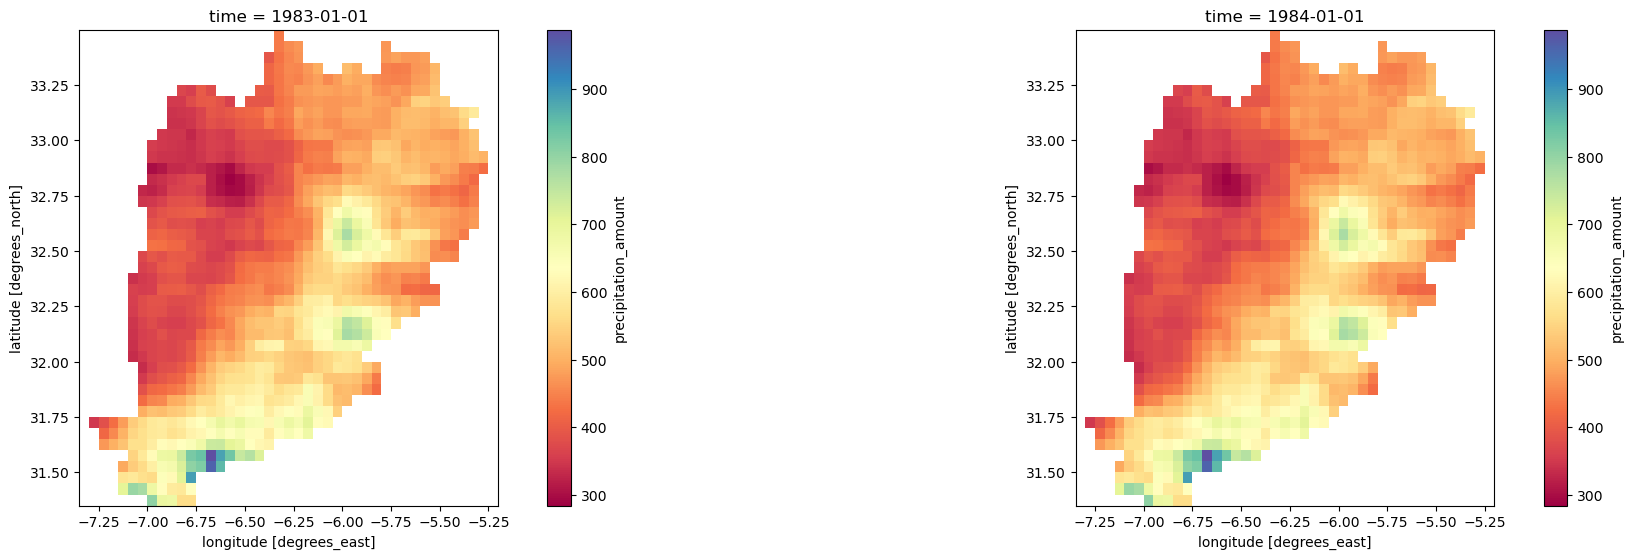

In [280]:
plt.figure(figsize=(40, 48))
for i in range(1, 3):
    ax = plt.subplot(9, 4, i)
    ds_bmk['precipitation_amount'][i].plot( cmap='Spectral', ax=ax)
    m.plot(ax = ax,color='black')
plt.tight_layout()

In [292]:
ds_sm.to_netcdf('Precipitation/SoussMassa/sm_precipitation_81_16.nc')

In [293]:
bmk_81_16 = xr.open_dataset('Precipitation/BeniMellalKhenifra/bmk_precipitation_81_16.nc')
tth_81_16 = xr.open_dataset('Precipitation/TangerTetouanAlHoceima/tth_precipitation_81_16.nc')
sm = xr.open_dataset('Precipitation/SoussMassa/sm_precipitation_81_16.nc')


In [294]:
import warnings
warnings.filterwarnings('ignore')

In [366]:
def processing(file):
 ds = xr.open_dataset(file)
 df = ds.to_dataframe()
 m = df['precipitation_amount'].mean()
 return m

In [367]:
df = pd.DataFrame()

In [368]:
a  = processing("Precipitation/BeniMellalKhenifra/S_2004_2005.nc")
df =                          df.append({'Year':'2005','precipitation (mm)':np.round(a,2)}, ignore_index=True)

In [369]:
df = df.set_index('Year')

In [370]:
df

,precipitation (mm)
Year,
2005,350.79


In [335]:
df.to_excel('Precipitation/SoussMassa/precip_sm_81_16.xlsx',index=True)

In [358]:
bmk_t = pd.read_excel('Precipitation/BeniMellalKhenifra/precip_bmk_81_16.xlsx')
tth_t = pd.read_excel('Precipitation/TangerTetouanAlHoceima/precip_tth_81_16.xlsx')
sm_t = pd.read_excel('Precipitation/SoussMassa/precip_sm_81_16.xlsx')

In [359]:
tth_t = tth_t.rename(columns={'precipitation (mm)':'Tanger Tetouan Al Hoceima'})
bmk_t = bmk_t.rename(columns={'precipitation (mm)':'Beni Mellal Khenifra'})
sm_t = sm_t.rename(columns={'precipitation (mm)':'Souss Massa'})

In [360]:
bmk_t = bmk_t.set_index('Year')
tth_t = tth_t.set_index('Year')
sm_t = sm_t.set_index('Year')

In [362]:
ThreReg = pd.concat([tth_t,bmk_t,sm_t],axis=1)

In [380]:
thr.loc[2005,"Beni Mellal Khenifra"]=350.79

In [382]:
thr.to_excel('Precipitation/precip_3Region_81_16.xlsx',index=True)

<center><h1 style='color:aqua'>Temperature</h1></center>

<center><h2 style='color:Orange'>ERA5</h2></center>

In [5]:
#Data Manipulation specific
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
from scipy import signal
from netCDF4 import Dataset
#Visualisation specific
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline

# For splitting the data into Train and Test set
from sklearn.model_selection import train_test_split

In [6]:
import cdsapi
import xarray as xr
from urllib.request import urlopen# start the client

In [341]:
import requests

r = requests.get("http://google.com")       
print(r.status_code)

200


In [342]:
import certifi
import urllib3
http = urllib3.PoolManager(
    cert_reqs='CERT_REQUIRED',
    ca_certs=certifi.where()
)

In [343]:
cds = cdsapi.Client()# dataset you want to read

In [344]:
url = 'url: https://cds.climate.copernicus.eu/api/v2'
key = 'key: 129347:91293d5f-ec5b-4b19-bf59-560030a3fefc'

with open('C:/Users/Lahcen.OUSAYD/.cdsapirc', 'w') as f:
    f.write('\n'.join([url, key]))

with open('C:/Users/Lahcen.OUSAYD/.cdsapirc') as f:
    print(f.read())

url: https://cds.climate.copernicus.eu/api/v2
key: 129347:91293d5f-ec5b-4b19-bf59-560030a3fefc


In [346]:
import cdsapi

c = cdsapi.Client()

c.retrieve(
    'reanalysis-era5-land',
    {
        'format': 'netcdf',
        'variable': [
         '2m_temperature'
        ],
        'year':['1997','1998'],
      "product_type": "reanalysis",
       'month': [
                 '01','02','03','04','05','06','07','08','09','10','11','12'
                ],
          'day': [
              '01', '02', '03', '04', '05', '06',
              '07', '08', '09', 
               '10', '11', '12',
               '13', '14', '15', '16', '17', '18',
               '19', '20', '21', '22', '23', '24',
               '25', '26', '27', '28', '29', '30',
               '31'
          ],
          'area': [
                 37.1,-18.41,20.43,0.18  
          ],
    },
    'datasets.nc')

2023-01-17 12:25:13,160 INFO Welcome to the CDS
2023-01-17 12:25:13,161 INFO Sending request to https://cds.climate.copernicus.eu/api/v2/resources/reanalysis-era5-land
2023-01-17 12:25:13,382 INFO Request is queued
2023-01-17 12:25:14,503 INFO Request is running
2023-01-17 12:28:06,131 INFO Request is completed
2023-01-17 12:28:06,133 INFO Downloading https://download-0010-clone.copernicus-climate.eu/cache-compute-0010/cache/data9/adaptor.mars.internal-1673954853.9799862-5374-14-bf939784-7d2b-4e96-9c47-5a86fff5782c.nc to datasets.nc (43.3M)
2023-01-17 12:28:36,972 INFO Download rate 1.4M/s   


Result(content_length=45355924,content_type=application/x-netcdf,location=https://download-0010-clone.copernicus-climate.eu/cache-compute-0010/cache/data9/adaptor.mars.internal-1673954853.9799862-5374-14-bf939784-7d2b-4e96-9c47-5a86fff5782c.nc)

<center><h2 style='color:Orange'>ERA5 Processing</h2></center>

In [347]:
t_1981_1982 = xr.open_dataset('Temperature/YEARS/1981_1982.nc')
t_1983_1984 = xr.open_dataset('Temperature/YEARS/1983_1984.nc')
t_1985_1986 = xr.open_dataset('Temperature/YEARS/1985_1986.nc')
t_1987_1988 = xr.open_dataset('Temperature/YEARS/1987_1988.nc')
t_1989_1990 = xr.open_dataset('Temperature/YEARS/1989_1990.nc')
t_1991_1992 = xr.open_dataset('Temperature/YEARS/1991_1992.nc')
t_1993_1994 = xr.open_dataset('Temperature/YEARS/1993_1994.nc')
t_1995_1996 = xr.open_dataset('Temperature/YEARS/1995_1996.nc')
t_1997_1998 = xr.open_dataset('Temperature/YEARS/1997_1998.nc')
t_1999 = xr.open_dataset('Temperature/YEARS/1999.nc')

In [348]:
t_2000_2001 = xr.open_dataset('Temperature/YEARS/2000_2001.nc')
t_2002_2003 = xr.open_dataset('Temperature/YEARS/2002_2003.nc')
t_2004_2005 = xr.open_dataset('Temperature/YEARS/2004_2005.nc')
t_2006_2007 = xr.open_dataset('Temperature/YEARS/2006_2007.nc')
t_2008_2009 = xr.open_dataset('Temperature/YEARS/2008_2009.nc')
t_2010_2011 = xr.open_dataset('Temperature/YEARS/2010_2011.nc')
t_2012_2013 = xr.open_dataset('Temperature/YEARS/2012_2013.nc')
t_2014_2015 = xr.open_dataset('Temperature/YEARS/2014_2015.nc')
t_2016 = xr.open_dataset('Temperature/YEARS/2016.nc')

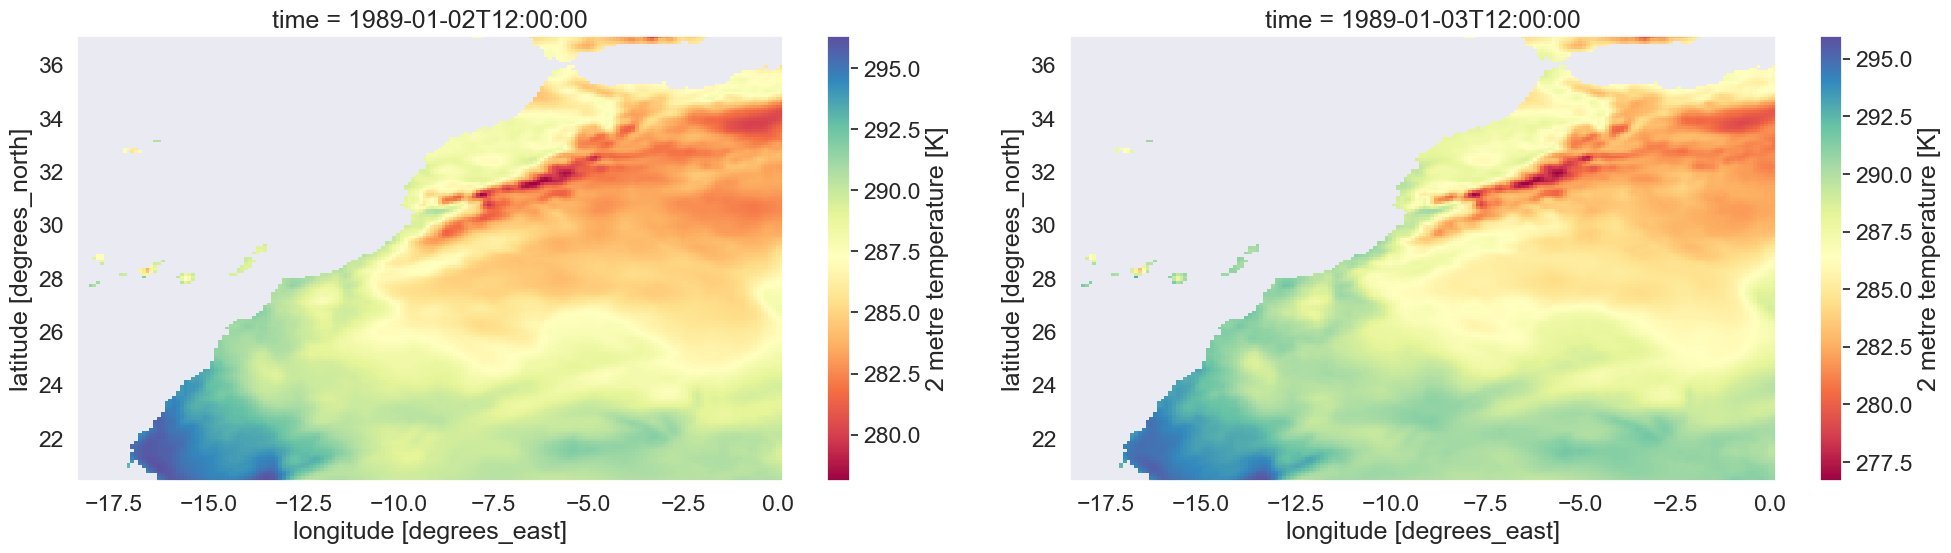

In [349]:
plt.figure(figsize=(40, 48))
for i in range(1, 3):
    ax = plt.subplot(9, 4, i)
    t_1989_1990['t2m'][i].plot( cmap='Spectral', ax=ax)
plt.tight_layout()

In [350]:
ds_temp = xr.combine_nested([t_1981_1982,t_1983_1984,t_1985_1986,t_1987_1988,t_1989_1990,t_1991_1992,t_1993_1994,t_1995_1996,t_1997_1998,
                           t_1999,t_2000_2001,t_2002_2003,t_2004_2005,t_2006_2007,t_2008_2009,t_2010_2011,t_2012_2013,t_2014_2015,t_2016], concat_dim=["time"])

In [352]:
ds_temp.to_netcdf('Temperature/YEARS/t2m__1981_2016.nc')

In [392]:
ds = xr.open_dataset('Temperature/merge/Temperature_1981_2016_F32.nc')

In [393]:
ds.info()

xarray.Dataset {
dimensions:
	time = 13149 ;
	longitude = 186 ;
	latitude = 167 ;

variables:
	datetime64[ns] time(time) ;
		time:standard_name = time ;
		time:long_name = time ;
		time:axis = T ;
	float32 longitude(longitude) ;
		longitude:standard_name = longitude ;
		longitude:long_name = longitude ;
		longitude:units = degrees_east ;
		longitude:axis = X ;
	float32 latitude(latitude) ;
		latitude:standard_name = latitude ;
		latitude:long_name = latitude ;
		latitude:units = degrees_north ;
		latitude:axis = Y ;
	float32 t2m(time, latitude, longitude) ;
		t2m:long_name = 2 metre temperature ;
		t2m:units = K ;

// global attributes:
	:CDI = Climate Data Interface version 1.9.9rc1 (https://mpimet.mpg.de/cdi) ;
	:Conventions = CF-1.6 ;
	:history = Tue Jan 17 15:13:34 2023: cdo -b F32 mergetime 1981_1982.nc 1983_1984.nc 1985_1986.nc 1987_1988.nc 1989_1990.nc 1991_1992.nc 1993_1994.nc 1995_1996.nc 1997_1998.nc 1999.nc 2000_2001.nc 2002_2003.nc 2004_2005.nc 2006_2007.nc 2008_2009.nc 201

In [395]:
#mean_month = ds.resample(time='1M').mean()

In [384]:
#np.datetime64(pd.to_datetime(str(year_00_01.time.values[i-1])).strftime('%Y'))

In [260]:
a = 0
for i in range(8):
        a = year_81_82.t2m[:][i].mean()
        #a['time'] = np.datetime64(pd.to_datetime(str(year_81_82.time.values[i-1])).strftime('%Y'))
year_81_82.to_netcdf('Temperature/monthlyTemp/m_tt_1981_1982.nc')

<center><h2 style='color:Orange'>ERA5 Regions TTH</h2></center>

In [1]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from shapely.geometry import mapping
import rioxarray as rxr
import xarray as xr
import geopandas as gpd
import earthpy as et
import earthpy.plot as ep
# Prettier plotting with seaborn
sns.set(font_scale=1.5)

In [5]:
monthly_temp = xr.open_dataset("C:/Users/Lahcen.OUSAYD/Documents/Lahcen/A/Precipitation/maroc/Y_1981_2016.nc")

In [6]:
monthly_temp.time

<xarray.DataArray 'time' (time: 35)>
array(['1982-01-01T00:00:00.000000000', '1983-01-01T00:00:00.000000000',
       '1984-01-01T00:00:00.000000000', '1985-01-01T00:00:00.000000000',
       '1986-01-01T00:00:00.000000000', '1987-01-01T00:00:00.000000000',
       '1988-01-01T00:00:00.000000000', '1989-01-01T00:00:00.000000000',
       '1990-01-01T00:00:00.000000000', '1991-01-01T00:00:00.000000000',
       '1992-01-01T00:00:00.000000000', '1993-01-01T00:00:00.000000000',
       '1994-01-01T00:00:00.000000000', '1995-01-01T00:00:00.000000000',
       '1996-01-01T00:00:00.000000000', '1997-01-01T00:00:00.000000000',
       '1998-01-01T00:00:00.000000000', '1999-01-01T00:00:00.000000000',
       '2000-01-01T00:00:00.000000000', '2001-01-01T00:00:00.000000000',
       '2002-01-01T00:00:00.000000000', '2003-01-01T00:00:00.000000000',
       '2004-01-01T00:00:00.000000000', '2005-01-01T00:00:00.000000000',
       '2006-01-01T00:00:00.000000000', '2007-01-01T00:00:00.000000000',
       '2008-01-01T00:00:00.000000000', '2009-01-01T00:00:00.000000000',
       '2010-01-01T00:00:00.000000000', '2011-01-01T00:00:00.000000000',
       '2012-01-01T00:00:00.000000000', '2013-01-01T00:00:00.000000000',
       '2014-01-01T00:00:00.000000000', '2015-01-01T00:00:00.000000000',
       '2016-01-01T00:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 1982-01-01 1983-01-01 ... 2016-01-01

In [8]:
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
%xmode Minimal

Exception reporting mode: Minimal


In [9]:
monthly_temp['t2m'] = (monthly_temp['t2m'] -273.15)

In [25]:
monthly_temp.time.to_dataframe()[:3]

,time
time,
1980-12-31 12:00:00,1980-12-31 12:00:00
1981-01-30 00:00:00,1981-01-30 00:00:00
1981-02-28 12:00:00,1981-02-28 12:00:00


In [26]:
monthly_temp.t2m.max()

<xarray.DataArray 't2m' ()>
array(43.55651855)

In [27]:
tth_extent = gpd.read_file("shapfiles/Maroc/Maroc.shp")


In [28]:
tth_extent_p = gpd.read_file("shapfiles/Maroc/Maroc.shp").boundary

In [29]:
print('crop extent crs: ', tth_extent.crs)

crop extent crs:  epsg:4326


In [30]:
print('lidar crs: ', monthly_temp.rio.crs)

lidar crs:  None


In [31]:
monthly_temp = monthly_temp.rio.write_crs(tth_extent.crs)

In [32]:
print('lidar crs: ', tth_extent.crs)

lidar crs:  epsg:4326


In [33]:
#monthly_temp.time.to_dataframe()

In [34]:
monthly_temp = monthly_temp.drop(['time_bnds','spatial_ref'])

# Secour

In [252]:
m = gpd.read_file("All_55km/shapefiles/CasablancaSettat/CasablancaSettat.shp")
ha = xr.open_dataset("All_55km/Harvested_Area/M_HArea.nc")
y = xr.open_dataset("Precipitation/maroc_monthly_precipitation_81_16_orig_55km.nc")

In [238]:
#y= y.sel(time=~((y['time.month'] == 9) | (y['time.month'] == 10)))

In [254]:
y

<xarray.Dataset>
Dimensions:               (time: 432, bnds: 2, longitude: 32, latitude: 30)
Coordinates:
  * time                  (time) datetime64[ns] 1980-12-31 ... 2016-11-30
  * longitude             (longitude) float64 -16.75 -16.25 ... -1.75 -1.25
  * latitude              (latitude) float64 35.75 35.25 34.75 ... 21.75 21.25
Dimensions without coordinates: bnds
Data variables:
    time_bnds             (time, bnds) datetime64[ns] ...
    precipitation_amount  (time, latitude, longitude) float32 ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Sun May 21 23:45:27 2023: cdo remapnn,target_file.txt maroc...
    frequency:    mon
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [14]:


# Print the average yield
prec  = monthly_temp.rio.write_crs(CS_shp.crs)

avg = prec.rio.clip(CS_shp.geometry.apply(mapping),
                                      
                                      CS_shp.crs)

# Calculate the average across the time dimension
avg = avg['precipitation_amount'].mean(dim='time')

avg.to_netcdf('cumulative_precip_averaged_CS.nc')

In [17]:
avg

<xarray.DataArray 'precipitation_amount' (latitude: 31, longitude: 46)>
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)
Coordinates:
  * longitude    (longitude) float64 -9.025 -8.975 -8.925 ... -6.825 -6.775
  * latitude     (latitude) float64 32.32 32.37 32.42 ... 33.72 33.77 33.82
    spatial_ref  int32 0

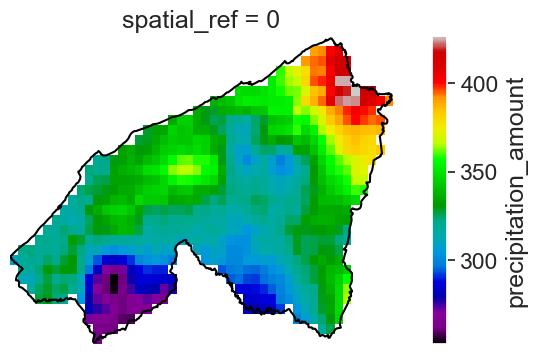

In [16]:
f, ax = plt.subplots(figsize=(10, 4))

CS_shp.boundary.plot(ax=ax,color='black')
avg.plot(ax=ax,
                            cmap = 'nipy_spectral',shading='auto'    )
#ax.set(title="Raster Layer Cropped to Geodataframe Extent")
ax.set_axis_off()
plt.show()

In [20]:
avg.to_netcdf('avreage_morocco_1982_2016_55_km.nc')

In [21]:
import geopandas as gpd

# Load the shapefiles for the five regions
region1_path = "All_55km/shapefiles/MarrakechSafi/MarrakechSafi.shp"
region2_path = "All_55km/shapefiles/BeniMellalKhenifra/BeniMellalKhenifra.shp"
region3_path = "All_55km/shapefiles/CasablancaSettat/CasablancaSettat.shp"
region4_path = "All_55km/shapefiles/FesMeknes/FesMeknes.shp"
region5_path = "All_55km/shapefiles/RabatSaleKenitra/"

# Read the shapefiles into GeoDataFrames
region1 = gpd.read_file(region1_path)
region2 = gpd.read_file(region2_path)
region3 = gpd.read_file(region3_path)
region4 = gpd.read_file(region4_path)
region5 = gpd.read_file(region5_path)

# Combine the five regions
combined_region = region1.append(region2).append(region3).append(region4).append(region5)

# Save the combined region as a new shapefile
output_path = "All_55km/shapefiles/combined_regions.shp"
combined_region.to_file(output_path)


C:\Users\Lahcen.OUSAYD\AppData\Local\Temp\ipykernel_12576\1737850912.py:18: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  combined_region = region1.append(region2).append(region3).append(region4).append(region5)
C:\Users\Lahcen.OUSAYD\AppData\Local\Temp\ipykernel_12576\1737850912.py:18: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  combined_region = region1.append(region2).append(region3).append(region4).append(region5)
C:\Users\Lahcen.OUSAYD\AppData\Local\Temp\ipykernel_12576\1737850912.py:18: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  combined_region = region1.append(region2).append(region3).append(region4).append(region5)


### SSSSSSSSSSSS

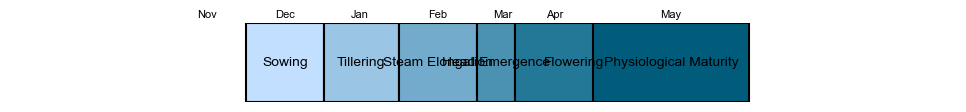

In [222]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Define the stages and their corresponding start and end positions
stages = [
    (76+15, 106+15, "Sowing"),
    (106+15, 135+15, "Tillering"),
    (135+15, 165+15, "Steam Elongation"),
    (165+15, 195, "Head Emergence"),
    (195, 225+15, "Flowering"),
    (225, 285, "Physiological Maturity")
]

#[[15 novomber to 15 December] ,sowing ] and [[15 December to 15 January],Tilering ], [[15 January to 15 February ],Steam elongation] ,
#[[15 February to 30 February],Head emergence],[[ 30 February to 15 April],Flowering ],[[15 April to 30 May],Physiological maturaty ]

# Create the figure and axes
fig, ax = plt.subplots(figsize=(10, 1.5))

# Remove the axes
ax.axis("off")

# Define colors for each stage
colors = ["#C2DFFF", "#9AC5E5", "#72ABCC", "#4A91B2", "#237797", "#005C7A"]

# Create the line segments for each stage
for i, stage in enumerate(stages):
    start_pos, end_pos, stage_name = stage
    line = patches.Rectangle((start_pos, 0), end_pos - start_pos, 10, facecolor=colors[i], edgecolor='black', linewidth=1.5)
    ax.add_patch(line)
    ax.text((start_pos + end_pos) / 2, 5, stage_name, ha='center', va='center', fontsize=10, color='black')

# Set the x-axis limits
ax.set_xlim(0, 365)

# Set the y-axis limits
ax.set_ylim(0, 10)

# Add the months outside the table
months = [
   ("Nov", 76), ("Dec", 106), ("Jan", 135), ("Feb", 165), ("Mar", 180), ("Apr", 210), ("May", 255),
    
]

for month, position in months:
    ax.text(position, 11, month, ha='center', va='center', fontsize=8, color='black')

# Show the plot
plt.tight_layout()
plt.show()


### SSSSS

In [198]:
bmk = gpd.read_file("shapfiles/Morocco/Morocco.shp")

In [216]:
ds= xr.open_dataset('morocco_potential_wheat_yield_10km.nc')

In [160]:
#ds = ds.resample(time = 'm', ).sum()

In [281]:
import xarray as xr

# Open the NetCDF file
dataset = xr.open_dataset('yield_Morocco_1981_2016.nc')

# Calculate the average across the time dimension
average_yield = dataset['yield'].mean(dim='time')

# Print the average yield
average_yield.to_netcdf('avreage_morocco_1982_2016_55km.nc')


PermissionError: [Errno 13] Permission denied: 'c:\\Users\\Lahcen.OUSAYD\\Documents\\Lahcen\\A\\avreage_morocco_1982_2016_55km.nc'

In [246]:
dataset = xr.open_dataset('morocco_potential_wheat_yield_10km_.nc')

In [280]:
ds1 = xr.open_dataset('morocco_potential_wheat_yield_10km_with_nan.nc')
ds2 = xr.open_dataset('average_Morocco_1982_2016_9km.nc')

# Perform subtraction
result = ds1 - ds2

# Save the result to a new NetCDF file
#result.to_netcdf('output_file.nc')

ValueError: Cannot apply_along_axis when any iteration dimensions are 0

In [247]:
import numpy as np
import xarray as xr

# Assuming your xarray DataArray is named 'yield_data'
# Replace the minimum value with nan
dataset = dataset.where(dataset != dataset.min(), np.nan)


In [248]:
dataset.to_netcdf('morocco_potential_wheat_yield_10km_with_nan.nc')

In [272]:
import xarray as xr
import numpy as np

# Read the input file (potential yields)
ds_potential_yields = xr.open_dataset('py/wheat_yieldpotential.tif')

# Define the target resolution (55km)
target_resolution = 55  # in kilometers

# Calculate the target grid shape based on the resolution
target_grid_shape = (
    int(180 / (target_resolution / 111.32)),  # latitude grid size
    int(360 / (target_resolution / 111.32)),  # longitude grid size
)

# Resample the potential yields to the target resolution
ds_potential_yields_resampled = ds_potential_yields.interp(
    x=np.linspace(-180, 180, target_grid_shape[1]),
    y=np.linspace(-90, 90, target_grid_shape[0]),
)

# Create a new xarray dataset for the resampled data
ds_resampled = xr.Dataset(
    {
        'yield': (('x', 'y'), ds_potential_yields_resampled['band'].data),
    },
    coords={
        'x': ds_potential_yields_resampled['y'],
        'y': ds_potential_yields_resampled['y'],
    },
)

# Save the resampled data to a new netCDF file
#ds_resampled.to_netcdf('resampled_potential_yields_55km.nc')


ValueError: Could not convert tuple of form (dims, data[, attrs, encoding]): (('x', 'y'), array([1])) to Variable.

In [273]:
ds_potential_yields

<xarray.Dataset>
Dimensions:      (band: 1, x: 4320, y: 2160)
Coordinates:
  * band         (band) int32 1
  * x            (x) float64 -180.0 -179.9 -179.8 -179.7 ... 179.8 179.9 180.0
  * y            (y) float64 89.96 89.87 89.79 89.71 ... -89.79 -89.88 -89.96
    spatial_ref  int32 ...
Data variables:
    band_data    (band, y, x) float32 ...

In [161]:
ds = ds.rio.write_crs(bmk.crs)

In [162]:
ds.t2m.mean()

<xarray.DataArray 't2m' ()>
array(15.312065, dtype=float32)
Coordinates:
    spatial_ref  int32 0

In [149]:
#ds = ds.drop('spatial_ref')
import geopandas as gpd

# Load the shapefiles for the five regions
region1_path = "All_55km/shapefiles/MarrakechSafi/MarrakechSafi.shp"
region2_path = "All_55km/shapefiles/BeniMellalKhenifra/BeniMellalKhenifra.shp"
region3_path = "All_55km/shapefiles/CasablancaSettat/CasablancaSettat.shp"
region4_path = "All_55km/shapefiles/FesMeknes/FesMeknes.shp"
region5_path = "All_55km/shapefiles/RabatSaleKenitra/"

# Read the shapefiles into GeoDataFrames
r1 = gpd.read_file(region1_path)
r2 = gpd.read_file(region2_path)
r3 = gpd.read_file(region3_path)
r4 = gpd.read_file(region4_path)
r5 = gpd.read_file(region5_path)

temp = xr.open_dataset("Temperature/merge/mean/Maroc/all_years_clipped_Morocco.nc")
temp = temp.rio.write_crs(r1.crs)

ms = temp.rio.clip(r1.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      r1.crs)

bmk = temp.rio.clip(r2.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      r2.crs)

cs = temp.rio.clip(r3.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      r3.crs)

fm = temp.rio.clip(r4.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      r4.crs)

rsk = temp.rio.clip(r5.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      r5.crs)

In [150]:
var = ms['t2m']
var.attrs.pop('grid_mapping', None)
ms = ms.drop(['spatial_ref'])

var = bmk['t2m']
var.attrs.pop('grid_mapping', None)
bmk = bmk.drop(['spatial_ref'])

var = cs['t2m']
var.attrs.pop('grid_mapping', None)
cs = cs.drop(['spatial_ref'])

var = fm['t2m']
var.attrs.pop('grid_mapping', None)
fm = fm.drop(['spatial_ref'])

var = rsk['t2m']
var.attrs.pop('grid_mapping', None)
rsk = rsk.drop(['spatial_ref'])

In [151]:
ms.to_netcdf('ms_monthly_mean_temp_1982_2016.nc')

In [152]:
bmk.to_netcdf('bmk_monthly_mean_temp_1982_2016.nc')

In [153]:
cs.to_netcdf('cs_monthly_mean_temp_1982_2016.nc')

In [154]:
fm.to_netcdf('fm_monthly_mean_temp_1982_2016.nc')

In [155]:
rsk.to_netcdf('rsk_monthly_mean_temp_1982_2016.nc')

In [157]:
tt = xr.open_dataset('bmk_monthly_mean_temp_1982_2016_55km.nc')

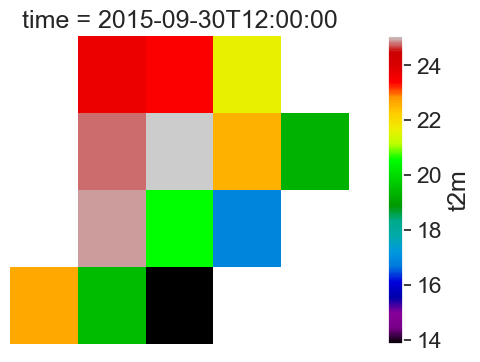

In [158]:
f, ax = plt.subplots(figsize=(10, 4))

m.boundary.plot(ax=ax,color='black')
tt['t2m'][302].plot(ax=ax,
                            cmap = 'nipy_spectral',shading='auto'    )
#ax.set(title="Raster Layer Cropped to Geodataframe Extent")
ax.set_axis_off()
plt.show()

In [164]:

bmk_clipped = ds.rio.clip(bmk.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      bmk.crs)


In [165]:
# Get the variable that is causing the issue
var = bmk_clipped['t2m']

# Remove the 'grid_mapping' attribute
var.attrs.pop('grid_mapping', None)


'spatial_ref'

In [166]:
bmk_clipped.to_netcdf('ms_monthly_min_temperature_9km.nc')

In [167]:
bmk_clipped

<xarray.Dataset>
Dimensions:      (time: 311, longitude: 29, latitude: 20)
Coordinates:
  * time         (time) datetime64[ns] 1981-10-31 ... 2016-05-31
  * longitude    (longitude) float32 -9.81 -9.71 -9.61 ... -7.21 -7.11 -7.01
  * latitude     (latitude) float32 32.73 32.63 32.53 ... 31.03 30.93 30.83
    spatial_ref  int32 0
Data variables:
    t2m          (time, latitude, longitude) float32 nan nan nan ... nan nan nan

<closed DatasetReader name='py/wheat_yieldpotential.tif' mode='r'>

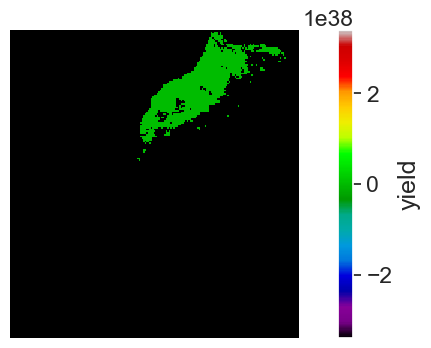

In [215]:
f, ax = plt.subplots(figsize=(10, 4))

bmk.plot(ax=ax,color='white')
dataset['yield'].plot(ax=ax,
                            cmap = 'nipy_spectral',shading='auto'    )
#ax.set(title="Raster Layer Cropped to Geodataframe Extent")
ax.set_axis_off()
plt.show()


# End Secour 

In [35]:
monthly_temp

<xarray.Dataset>
Dimensions:    (time: 432, longitude: 186, latitude: 167)
Coordinates:
  * time       (time) datetime64[ns] 1980-12-31T12:00:00 ... 2016-11-30T12:00:00
  * longitude  (longitude) float32 -18.41 -18.31 -18.21 ... -0.11 -0.01 0.09
  * latitude   (latitude) float32 37.03 36.93 36.83 36.73 ... 20.63 20.53 20.43
Data variables:
    t2m        (time, latitude, longitude) float32 nan nan nan ... 20.04 19.91
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Tue Jan 17 23:46:45 2023: cdo shifttime,-16days Temperature...
    frequency:    mon
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [36]:
monthly_temp = monthly_temp.rio.write_crs(tth_extent.crs)

In [37]:
tth_clipped = monthly_temp.rio.clip(tth_extent.geometry.apply(mapping),
                                      # This is needed if your GDF is in a diff CRS than the raster data
                                      tth_extent.crs)

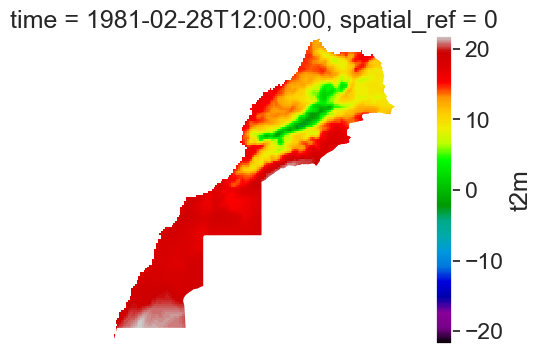

In [38]:


f, ax = plt.subplots(figsize=(10, 4))

tth_extent_p.plot(ax=ax,color='white')
tth_clipped.t2m[2].plot(ax=ax,
                            cmap = 'nipy_spectral',shading='auto'    )
#ax.set(title="Raster Layer Cropped to Geodataframe Extent")
ax.set_axis_off()
plt.show()


In [39]:
tth_clipped.time.to_dataframe()[:5]

,spatial_ref,time
time,,
1980-12-31 12:00:00,0,1980-12-31 12:00:00
1981-01-30 00:00:00,0,1981-01-30 00:00:00
1981-02-28 12:00:00,0,1981-02-28 12:00:00
1981-03-31 00:00:00,0,1981-03-31 00:00:00
1981-04-30 12:00:00,0,1981-04-30 12:00:00


In [40]:
ds = tth_clipped

In [41]:
year_81_82 = ds.sel(time=slice('1981-10-30', '1982-05-31'))

year_82_83 = ds.sel(time=slice('1982-10-30', '1983-05-31'))

year_83_84 = ds.sel(time=slice('1983-10-30', '1984-05-31'))

year_84_85 = ds.sel(time=slice('1984-10-30', '1985-05-31'))

year_85_86 = ds.sel(time=slice('1985-10-30', '1986-05-31'))

year_86_87 = ds.sel(time=slice('1986-10-30', '1987-05-30'))

year_87_88 = ds.sel(time=slice('1987-10-30', '1988-05-31'))

year_88_89 = ds.sel(time=slice('1988-10-30', '1989-05-31'))

year_89_90 = ds.sel(time=slice('1989-10-30', '1990-05-31'))

year_90_91 = ds.sel(time=slice('1990-10-30', '1991-05-31'))

year_91_92 = ds.sel(time=slice('1991-10-30', '1992-05-31'))

year_92_93 = ds.sel(time=slice('1992-10-30', '1993-05-31'))

year_93_94 = ds.sel(time=slice('1993-10-30', '1994-05-31'))

year_94_95 = ds.sel(time=slice('1994-10-30', '1995-05-31'))

year_95_96 = ds.sel(time=slice('1995-10-30', '1996-05-31'))

year_96_97 = ds.sel(time=slice('1996-10-30', '1997-05-31'))

year_97_98 = ds.sel(time=slice('1997-10-30', '1998-05-31'))

year_98_99 = ds.sel(time=slice('1998-10-30', '1999-05-31'))

year_99_100 = ds.sel(time=slice('1999-10-30', '2000-05-31'))

year_100_01 = ds.sel(time=slice('2000-10-30', '2001-05-31'))

year_01_02 = ds.sel(time=slice('2001-10-30', '2002-05-31'))

year_02_03 = ds.sel(time=slice('2002-10-30', '2003-05-31'))

year_03_04 = ds.sel(time=slice('2003-10-30', '2004-05-31'))

year_04_05 = ds.sel(time=slice('2004-10-30', '2005-05-31'))

year_05_06 = ds.sel(time=slice('2005-10-30', '2006-05-31'))

year_06_07 = ds.sel(time=slice('2006-10-30', '2007-05-31'))

year_07_08 = ds.sel(time=slice('2007-10-30', '2008-05-31'))

year_08_09 = ds.sel(time=slice('2008-10-30', '2009-05-31'))

year_09_10 = ds.sel(time=slice('2009-10-30', '2010-05-30'))

year_10_11 = ds.sel(time=slice('2010-10-30', '2011-05-31'))

year_11_12 = ds.sel(time=slice('2011-10-30', '2012-05-31'))

year_12_13 = ds.sel(time=slice('2012-10-30', '2013-05-31'))

year_13_14 = ds.sel(time=slice('2013-10-30', '2014-05-31'))

year_14_15 = ds.sel(time=slice('2014-10-30', '2015-05-31'))

year_15_16 = ds.sel(time=slice('2015-10-30', '2016-05-31'))

In [42]:
ds

<xarray.Dataset>
Dimensions:      (time: 432, longitude: 164, latitude: 155)
Coordinates:
  * time         (time) datetime64[ns] 1980-12-31T12:00:00 ... 2016-11-30T12:...
  * longitude    (longitude) float32 -17.31 -17.21 -17.11 ... -1.21 -1.11 -1.01
  * latitude     (latitude) float32 36.03 35.93 35.83 ... 20.83 20.73 20.63
    spatial_ref  int32 0
Data variables:
    t2m          (time, latitude, longitude) float32 nan nan nan ... nan nan nan
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Tue Jan 17 23:46:45 2023: cdo shifttime,-16days Temperature...
    frequency:    mon
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

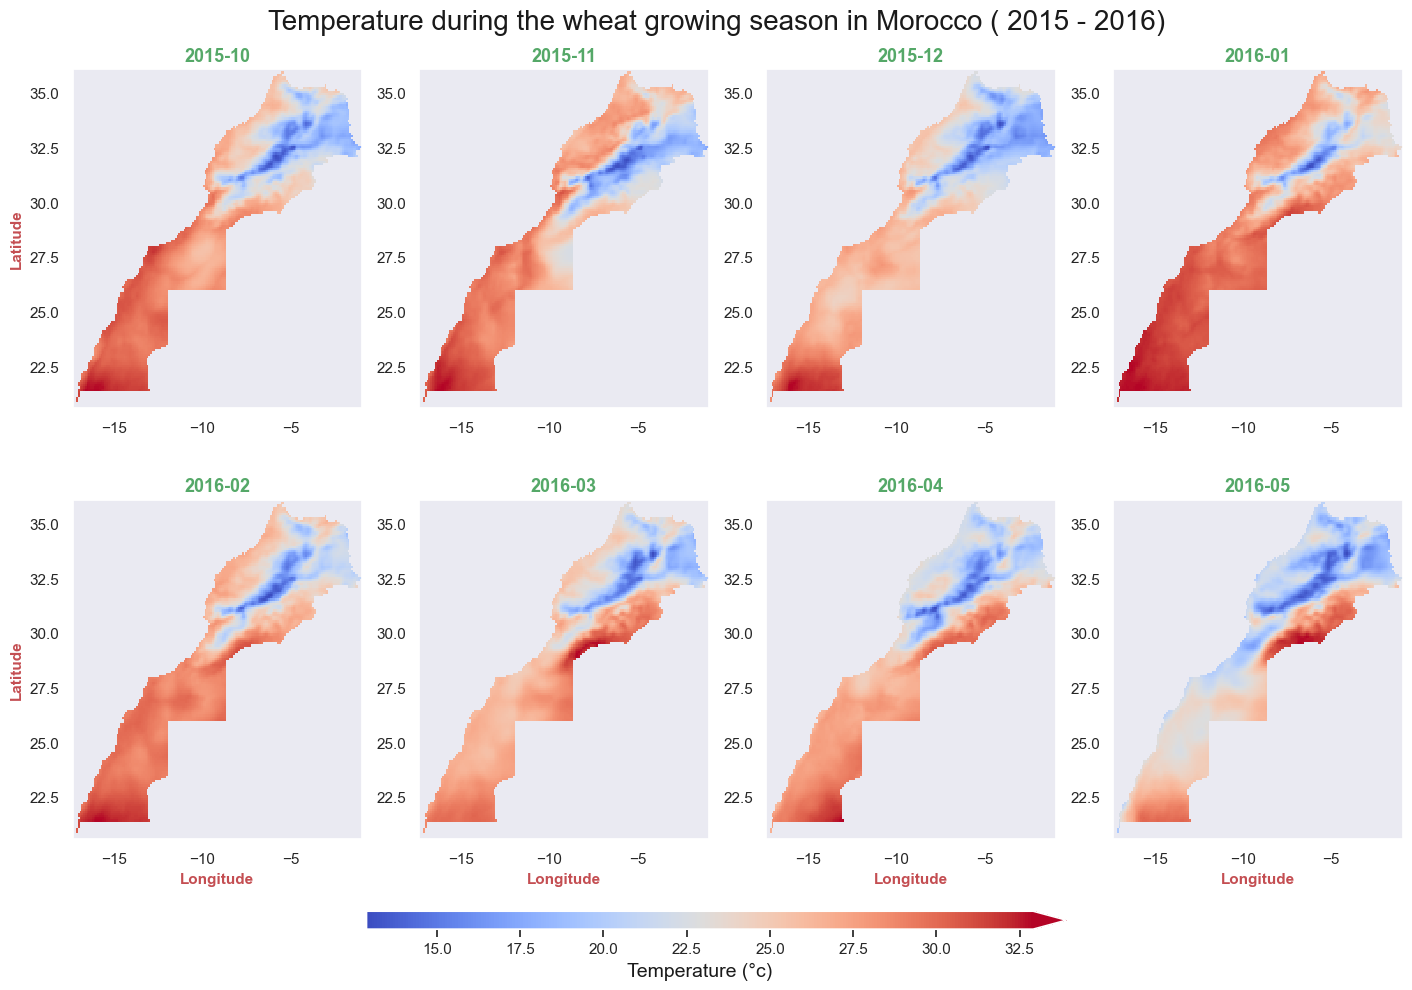

In [44]:
fig = plt.figure(figsize=[14,10], facecolor='w')

plt.subplots_adjust(bottom=0.15, top=0.96, left=0.04, right=0.99, 
                    wspace=0.2, hspace=0.27) # wspace and hspace adjust the horizontal and vertical spaces, respectively.
nrows = 2
ncols = 4
for i in range(1, 9):
    plt.subplot(nrows, ncols, i)
    dataplot = year_15_16.t2m[i-1, :, :] # Remember that in Python, the data index starts at 0, but the subplot index start at 1.
    p = plt.pcolormesh(year_97_98.longitude, year_97_98.latitude, dataplot,
                     #vmax = 80, vmin = 0,
                     cmap = 'coolwarm',shading='auto'
                   ) 
    #plt.xlim([233,295])
    #plt.ylim([25,50])
    plt.title(pd.to_datetime(str(year_15_16.time.values[i-1])).strftime('%Y-%m'), fontsize = 13, 
              fontweight = 'bold', color = 'g')
    plt.xticks(fontsize = 11)
    plt.yticks(fontsize = 11)
    if i % ncols == 1: # Add ylabel for the very left subplots
        plt.ylabel('Latitude', fontsize = 11, fontweight = 'bold',color = 'r')
    if i > ncols*(nrows-1): # Add xlabel for the bottom row subplots
        plt.xlabel('Longitude', fontsize = 11, fontweight = 'bold',color = 'r')
    
# Add a colorbar at the bottom:
cax = fig.add_axes([0.25, 0.06, 0.5, 0.018])
cb = plt.colorbar(cax=cax, orientation='horizontal', extend = 'max',)
cb.ax.tick_params(labelsize=11)
cb.set_label(label='Temperature (°c)', color = 'k', size=14)
fig.suptitle('Temperature during the wheat growing season in Morocco ( 2015 - 2016)',size=20,color = 'k')
fig.subplots_adjust(top=0.92)
# Now we can save a high resolution (300dpi) version of the figure:
#plt.savefig('Fig_prec_cpc_mon_2012.png', format = 'png', dpi = 300)

In [686]:
pd.to_datetime(str(year_81_82.time.values[7])).strftime('%Y-%m')

'1982-05'

In [687]:
ds_tth = xr.combine_nested([year_81_82,year_82_83,year_83_84,year_84_85,year_85_86,year_86_87,year_87_88,year_88_89,year_89_90,year_90_91,year_91_92,year_92_93,
                             year_93_94,year_94_95,year_95_96,year_96_97,year_97_98,year_98_99,year_99_00,year_00_01,year_01_02,year_02_03,year_03_04,year_04_05,
                             year_05_06,year_06_07,year_07_08,year_08_09,year_09_10,year_10_11,year_11_12,year_12_13,year_13_14,year_14_15,year_15_16], concat_dim=["time"])

In [688]:
ds_tth = ds_tth.drop('spatial_ref')

In [689]:
# Write the data to a new geotiff file
ds_tth.to_netcdf('Temperature/merge/min/WGS_Temperature_1981_2016_monthly_min_Morocco.nc')

In [690]:
ds_t = xr.open_dataset('Temperature/merge/min/WGS_Temperature_1981_2016_monthly_min_Morocco.nc')

In [691]:
ds_t

<xarray.Dataset>
Dimensions:    (time: 311, longitude: 164, latitude: 155)
Coordinates:
  * time       (time) datetime64[ns] 1981-10-31 ... 2016-05-31
  * longitude  (longitude) float32 -17.31 -17.21 -17.11 ... -1.21 -1.11 -1.01
  * latitude   (latitude) float32 36.03 35.93 35.83 35.73 ... 20.83 20.73 20.63
Data variables:
    t2m        (time, latitude, longitude) float32 ...

In [692]:
import warnings
warnings.filterwarnings('ignore')

In [693]:
def processing_(file):
 df = file.to_dataframe()
 m = df['t2m'].mean()
 return m


In [695]:
dt = pd.DataFrame()

In [730]:
a  =  processing_(year_15_16)
dt = dt.append({'Year':'2016','temperature (°C)':np.round(a,2)}, ignore_index=True)

In [731]:
dt=dt.set_index('Year')

In [732]:
len(dt)

35

In [733]:
dt['temperature (°C)'].max()

16.3

In [734]:
dt

,temperature (°C)
Year,
1982,15.33
1983,15.01
1984,15.92
1985,15.11
1986,15.03
1987,14.93
1988,14.70
1989,14.80
1990,15.92


<AxesSubplot:xlabel='Year'>

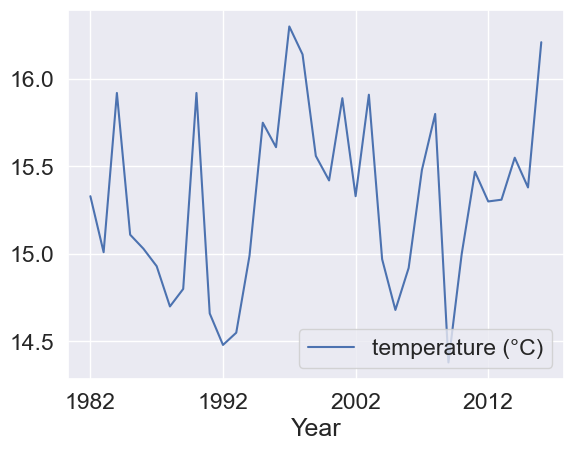

In [735]:
dt.plot()

In [736]:
dt.to_excel('Temperature/merge/min/WGS_Temperature_1981_2016_monthly_min_Morocco.xlsx')

In [359]:
e = pd.read_excel('Temperature/merge/max/WGS_Temperature_1981_2016_monthly_max_BeniMellalKhenifra.xlsx')

In [755]:
tthmean = pd.read_excel('Temperature/merge/min/WGS_Temperature_1981_2016_monthly_min_TangerTetouanAlHoceima.xlsx')
bmkmean = pd.read_excel('Temperature/merge/min/WGS_Temperature_1981_2016_monthly_min_BeniMellalKhenifra.xlsx')
smmean = pd.read_excel('Temperature/merge/min/WGS_Temperature_1981_2016_monthly_min_soussMassa.xlsx')
#e3 = pd.read_excel('temp_Morocco_81_16.xlsx')


In [756]:
tthmean = tthmean.set_index('Year')
bmkmean = bmkmean.set_index('Year')
smmean = smmean.set_index('Year')

In [757]:
tthmean.rename(columns = {'temperature (°C)':'Tanger Tetouan Al Hoceima'}, inplace = True)
bmkmean.rename(columns = {'temperature (°C)':'Beni Mellal Khenifra'}, inplace = True)
smmean.rename(columns = {'temperature (°C)':'Souss Massa'}, inplace = True)

In [761]:
temp_3reg = pd.concat([temp_3reg_max,temp_3reg_mean,temp_3reg_min,],axis = 1)

In [762]:
temp_3reg

,Tanger Tetouan Al Hoceima,Beni Mellal Khenifra,Souss Massa,Tanger Tetouan Al Hoceima,Beni Mellal Khenifra,Souss Massa,Tanger Tetouan Al Hoceima,Beni Mellal Khenifra,Souss Massa
Year,,,,,,,,,
1982,22.98,23.50,26.60,17.77,17.33,21.47,12.79,9.95,15.98
1983,22.94,23.42,27.30,17.29,17.44,21.83,11.56,8.86,15.89
1984,21.74,23.35,27.16,17.05,17.24,21.79,12.32,10.05,16.51
1985,22.29,22.71,26.63,17.20,16.84,21.21,12.12,9.06,15.79
1986,23.68,23.82,27.42,17.33,16.62,21.51,11.97,8.59,15.26
1987,22.94,23.47,26.48,17.17,17.24,21.20,11.43,9.71,15.37
1988,22.68,22.99,26.70,17.21,16.51,21.12,11.91,8.98,14.32
1989,22.55,22.57,26.17,17.66,16.79,20.67,12.08,8.72,14.56
1990,23.41,23.32,27.34,18.35,17.86,21.86,13.67,10.45,15.63


In [768]:
temp_3reg.to_excel('Temperature/merge/temp3regmaxmeanmin.xlsx',index=True)

<center><h2 style='color:Orange'>Visualization</h2></center>

In [798]:
tmp = pd.read_excel('Temperature/merge/temp3regmaxmeanmin.xlsx',header=[0,1],index_col=[0])

In [799]:
tmp.head()

Max Temperature                                   \
Year Tanger Tetouan Al Hoceima Beni Mellal Khenifra Souss Massa   
1982                     22.98                23.50       26.60   
1983                     22.94                23.42       27.30   
1984                     21.74                23.35       27.16   
1985                     22.29                22.71       26.63   
1986                     23.68                23.82       27.42   

              Mean Temperature                                   \
Year Tanger Tetouan Al Hoceima Beni Mellal Khenifra Souss Massa   
1982                     17.77                17.33       21.47   
1983                     17.29                17.44       21.83   
1984                     17.05                17.24       21.79   
1985                     17.20                16.84       21.21   
1986                     17.33                16.62       21.51   

               Min Temperature                                   
Year Tanger Tetouan Al Hoceima Beni Mellal Khenifra Souss Massa  
1982                     12.79                 9.95       15.98  
1983                     11.56                 8.86       15.89  
1984                     12.32                10.05       16.51  
1985                     12.12                 9.06       15.79  
1986                     11.97                 8.59       15.26

<AxesSubplot:>

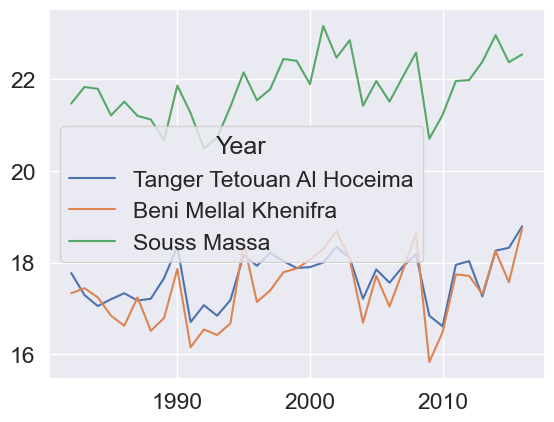

In [800]:
tmp['Mean Temperature'].plot()

In [70]:
t = xr.open_dataset("Temperature/merge/mean/TangerTetouanAlHoceima/all_years_clipped_TangerTetouanAlHoceima.nc")

In [71]:
t.time

<xarray.DataArray 'time' (time: 311)>
array(['1981-10-31T00:00:00.000000000', '1981-11-30T12:00:00.000000000',
       '1981-12-31T12:00:00.000000000', ..., '2016-03-31T00:00:00.000000000',
       '2016-04-30T12:00:00.000000000', '2016-05-31T00:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 1981-10-31 1981-11-30T12:00:00 ... 2016-05-31

In [72]:
t = t.resample(time= 'y').mean()

In [73]:
#t['t2m'] = t.t2m -273.15

In [74]:
t

<xarray.Dataset>
Dimensions:    (latitude: 14, longitude: 25, time: 36)
Coordinates:
  * latitude   (latitude) float32 35.83 35.73 35.63 35.53 ... 34.73 34.63 34.53
  * longitude  (longitude) float32 -6.21 -6.11 -6.01 -5.91 ... -4.01 -3.91 -3.81
  * time       (time) datetime64[ns] 1981-12-31 1982-12-31 ... 2016-12-31
Data variables:
    t2m        (time, latitude, longitude) float32 nan nan nan ... nan nan nan

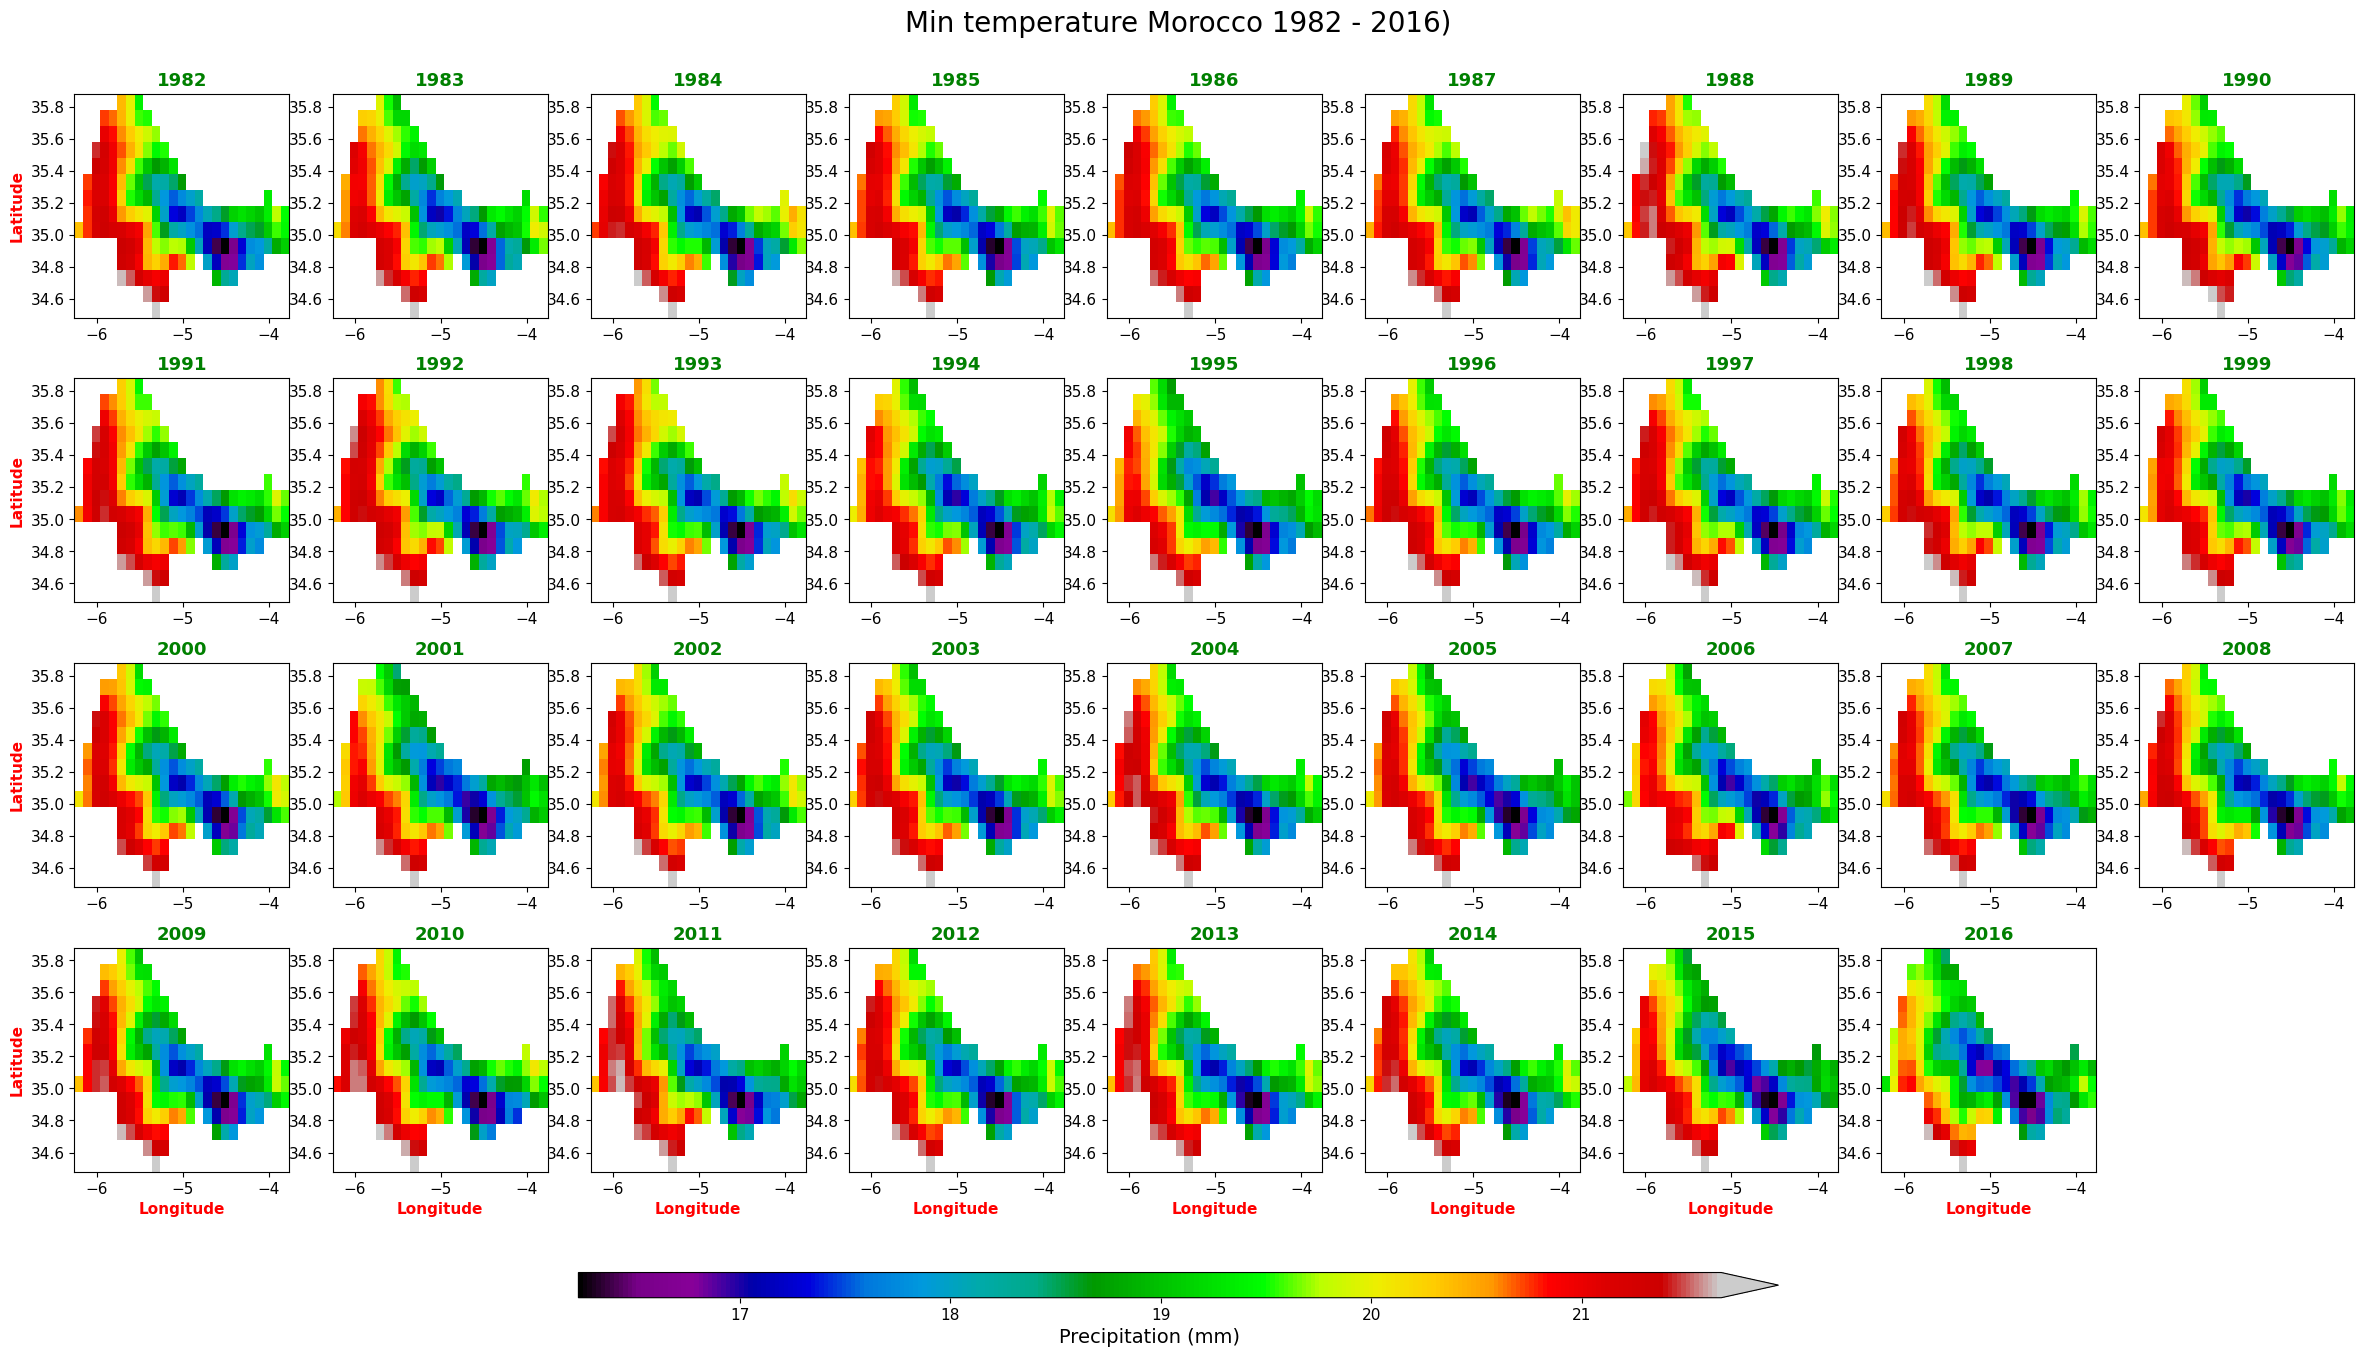

In [75]:
fig = plt.figure(figsize=[24,14], facecolor='w')
#cubehelix_r _ gist_earth
plt.subplots_adjust(bottom=0.15, top=0.96, left=0.04, right=0.99, 
                    wspace=0.2, hspace=0.27) # wspace and hspace adjust the horizontal and vertical spaces, respectively.
nrows = 4
ncols = 9
for i in range(1, 36):
    plt.subplot(nrows, ncols, i)
    dataplot = t.t2m[i, :, :]# Remember that in Python, the data index starts at 0, but the subplot index start at 1.
    p = plt.pcolormesh(t.longitude, t.latitude, dataplot,
                     #vmax = 300, vmin = 0,
                     cmap = 'nipy_spectral',shading='auto'
                   ) 
    #plt.xlim([233,295])
    #plt.ylim([25,50])
    plt.title(pd.to_datetime(str(t.time.values[i])).strftime('%Y'), fontsize = 13, 
              fontweight = 'bold', color = 'g')
    plt.xticks(fontsize = 11)
    plt.yticks(fontsize = 11)
    if i % ncols == 1: # Add ylabel for the very left subplots
        plt.ylabel('Latitude', fontsize = 11, fontweight = 'bold',color = 'r')
    if i > ncols*(nrows-1): # Add xlabel for the bottom row subplots
        plt.xlabel('Longitude', fontsize = 11, fontweight = 'bold',color = 'r')
    
# Add a colorbar at the bottom:
cax = fig.add_axes([0.25, 0.06, 0.5, 0.018])
cb = plt.colorbar(cax=cax, orientation='horizontal', extend = 'max',)
cb.ax.tick_params(labelsize=11)
cb.set_label(label='Precipitation (mm)', color = 'k', size=14)
fig.suptitle('Min temperature Morocco 1982 - 2016)',size=20,color = 'k')
fig.subplots_adjust(top=0.92)
# Now we can save a high resolution (300dpi) version of the figure:
#plt.savefig('Fig_prec_.png', format = 'png', dpi = 700)

In [76]:
t.to_netcdf("Temperature/merge/mean/TangerTetouanAlHoceima/all_years_clipped_yearly_TangerTetouanAlHoceima.nc")

In [15]:
import os
import errno
import glob 
import time 
import win32com.client    

In [46]:
from xls2xlsx import XLS2XLSX
x2x = XLS2XLSX("D:/ABHT_Pluie_Journaliere_1970_2010/SIDI HSSAINE.xls")
x2x.to_xlsx("D:/results/SIDI HSSAINE.xlsx")

'D:/results/SIDI HSSAINE.xlsx'

In [5]:
import plotly.express as px
import xarray as xr
import pandas as pd

# Load the first NetCDF time series dataset
ds1 = xr.open_dataset('timeseries1.nc')

# Extract the relevant data arrays
time1 = ds1['time'].values
data1 = ds1['variable_of_interest_1'].values

# Load the second NetCDF time series dataset
ds2 = xr.open_dataset('timeseries2.nc')

# Extract the relevant data arrays
time2 = ds2['time'].values
data2 = ds2['variable_of_interest_2'].values

# Combine the data into a single DataFrame
df = pd.DataFrame({'Time': np.concatenate((time1, time2)),
                   'Data': np.concatenate((data1.flatten(), data2.flatten())),
                   'Dataset': ['Dataset 1']*len(time1) + ['Dataset 2']*len(time2)})

# Create the density heatmap
fig = px.density_heatmap(df, x='Time', y='Data', color='Dataset',
                         nbinsx=50, nbinsy=50,
                         color_discrete_sequence=['red', 'blue'],
                         title='Density Heatmap of Time and Data for Two Datasets',
                         xaxis_title='Time', yaxis_title='Data')

# Show the plot
fig.show()


c:\Users\Lahcen.OUSAYD\Anaconda3\lib\site-packages\ecmwflibs\__init__.py:83: UserWarning:

DLL load failed while importing _ecmwflibs: The specified procedure could not be found.

c:\Users\Lahcen.OUSAYD\Anaconda3\lib\site-packages\xarray\backends\plugins.py:71: RuntimeWarning:

Engine 'cfgrib' loading failed:
ecCodes library not found using ['eccodes', 'libeccodes.so', 'libeccodes']



FileNotFoundError: [Errno 2] No such file or directory: b'c:\\Users\\Lahcen.OUSAYD\\Documents\\Lahcen\\A\\timeseries1.nc'